<table style="width:100%; border-collapse:collapse; border-spacing:0; border:none; border-bottom:2px solid #e0e0e0; margin-bottom:16px; padding:0; margin-top:0;">
  <tr style="border:none; padding:0; margin:0;">
    <td style="width:144px; padding:16px 24px 16px 0; vertical-align:middle; border:none; outline:none; box-shadow:none;">
      <img src="https://github.com/TUIlmenauAMS/fs-ws2627-pinn-guitar/blob/main/assets/ams_group_tui.png?raw=1" width="120" style="border-radius:12px; display:block; margin:0;"/>
    </td>
    <td style="padding:16px 0 16px 0; vertical-align:middle; border:none; outline:none; box-shadow:none;">
      <h1 style="margin:0 0 4px 0; padding:0;">[WS26/27] Research Seminar / Forschungsseminar (MT und MIW)</h1>
      <h2 style="margin:0 0 8px 0; padding:0;">Physics-Informed Neural Networks for Stiff Guitar String Vibrations</h2>
      <h2 style="margin:0 0 8px 0; padding:0;">NB03: FDTD Simulation</h2>
      <p style="margin:0; padding:0;">
        <b>Institut für Medientechnik – Technische Universität Ilmenau</b><br>
        <a href="https://www.tu-ilmenau.de/universitaet/fakultaeten/fakultaet-elektrotechnik-und-informationstechnik/profil/institute-und-fachgebiete/fachgebiet-angewandte-mediensysteme" target="_blank">Institut für Medientechnik – AMS Group</a>
      </p>
      <p style="margin:4px 0 0 0; padding:0;">
        <b>Fachgebietsleiter:</b> Prof. Dr.-Ing. Gerald Schuller<br>
        <b>Wissenschaftlicher Mitarbeiter:</b> Renato Fera P. <a href="https://www.linkedin.com/in/renato-profeta/" target="_blank">LinkedIn</a>
      </p>
    </td>
  </tr>
</table>

In [2]:
# ── Environment detection ──────────────────────────────────────────────────────
import sys, subprocess

def _in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _pip_install(package, label=None):
    """Install one package via pip; print success or the full error output."""
    label = label or package
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", package],
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"  ✓ {label} installed.")
    else:
        print(f"  ✗ {label} install FAILED (exit {result.returncode}):")
        for line in (result.stderr or result.stdout or "").strip().splitlines():
            print(f"    {line}")

if _in_colab():
    print("Colab detected — installing packages (this takes ~60 s on first run) ...")
    _pip_install("numpy",      "numpy")
    _pip_install("matplotlib", "matplotlib")
    _pip_install("scipy",      "scipy")
    _pip_install("numba",      "numba")
    _pip_install("py-pde",        "py-pde")
    _pip_install("devito",     "devito")
    print("Installation step complete. Verifying imports below ...")
else:
    print("✓ Local / Codespaces — using uv-managed venv.")
    print("  If any import errors appear below, run in your terminal:")
    print("    sudo apt-get install -y gcc   # required by Devito at runtime")
    print("    uv sync --group nb03          # installs numba, pde, devito")

import numpy as np
import matplotlib.pyplot as plt
import scipy

try:
    import numba
    print(f"✓ Numba {numba.__version__} ready.")
except ImportError:
    print("✗ Numba not found.")

try:
    import pde
    print(f"✓ py-pde {pde.__version__} ready.")
except ImportError as e:
    print(f"✗ py-pde import failed: {e}")

try:
    import devito
    print(f"✓ Devito {devito.__version__} ready.")
except ImportError:
    print("✗ Devito not found.")
except Exception as e:
    print(f"✗ Devito import error (gcc missing?): {e}")
    print("  Run: sudo apt-get install -y gcc   then restart the kernel.")

print(f"✓ NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__} | "
      f"SciPy {scipy.__version__} ready.")
# ──────────────────────────────────────────────────────────────────────────────

Colab detected — installing packages (this takes ~60 s on first run) ...
  ✓ numpy installed.
  ✓ matplotlib installed.
  ✓ scipy installed.
  ✓ numba installed.
  ✓ py-pde installed.
  ✓ devito installed.
Installation step complete. Verifying imports below ...
✓ Numba 0.64.0 ready.
✓ py-pde 0.60.0 ready.
✓ Devito 4.8.23 ready.
✓ NumPy 2.4.6 | Matplotlib 3.10.0 | SciPy 1.16.3 ready.


# NB03: FDTD Simulation

> **After this notebook you will be able to:**
> - Explain what FDTD is and how it differs from analytical and modal approaches
> - Explain the difference between the FDTD method and the FTCS scheme
> - Approximate derivatives on a grid using finite differences
> - Derive and implement the FTCS scheme for the 1D heat equation in NumPy
> - Explain the CFL stability condition and demonstrate numerical blow-up
> - Accelerate the same solver to near-C speed using NumPy + Numba
> - Solve the same problem with py-pde and understand when a high-level library helps
> - Run a Devito stencil and understand what production-grade PDE solvers do differently
> - **Compare all four numerical methods against the analytical solution from NB02**
> - **Quantify the error of each method using max absolute error and L² norm**

---

## 0. Shared problem definition

Before writing a single line of solver code, we fix the physical problem **once**.
Every solver in this notebook — NumPy, Numba, py-pde, Devito — will solve **exactly
this problem**, with **exactly these parameter values**. This is what makes the final
comparison meaningful.

**The problem** is the same as in NB02:

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2},
\qquad x \in [0, L],\; t \geq 0$$

with Dirichlet boundary conditions $u(0, t) = u(L, t) = 0$ and **uniform initial
condition** $f(x) = T_0$ (a rod held at a constant temperature, suddenly clamped to
ice-cold endpoints at $t = 0$).

> **Why $f(x) = T_0$ and not a triangle wave?**
> The analytical solution for this exact initial condition was derived step by step in
> [NB02](https://github.com/TUIlmenauAMS/fs-ws2627-pinn-guitar/blob/main/NB02_analytical_modal.ipynb).
> Using the same IC here lets us directly verify every numerical solver against a
> known ground truth.

The analytical solution (derived in NB02, used here as reference) is:

$$u(x, t) = \sum_{\substack{n=1 \\ n\,\text{odd}}}^{N}
  \frac{4 T_0}{n\pi}\sin\!\left(\frac{n\pi x}{L}\right)
  e^{-\alpha (n\pi/L)^2 t}$$

Only odd modes contribute because the uniform IC is an odd-symmetric function on the
extended domain $[-L, L]$.

> **Parameters below are intentionally isolated in one cell.** If you ever need to
> change $L$, $\alpha$, or $T_0$, change them here — all subsequent cells will
> automatically use the updated values.

In [3]:
# ── Shared physical parameters — identical to NB02 ────────────────────────────
L_val     = 1.0    # rod length [m]
alpha_val = 0.01   # thermal diffusivity [m²/s]
T0_val    = 1.0    # uniform initial temperature [°C or K, dimensionless here]
N_modes   = 50     # number of Fourier modes used in the analytical reference

# ── Shared numerical parameters ───────────────────────────────────────────────
Nx        = 100    # number of spatial grid points (including both endpoints)
T_end     = 5.0    # simulation end time [s]

# ── Snapshot times used in all comparison plots ───────────────────────────────
SNAP_TIMES = [0.5, 5.0]   # [s] — used in Section 7

# ── Initial condition: uniformly hot rod ──────────────────────────────────────
def ic_uniform(x):
    """f(x) = T0 everywhere — the IC from NB02."""
    return T0_val * np.ones_like(x)

# ── Analytical solution (from NB02, used here as ground truth) ────────────────
def analytical_solution(x, t, N=N_modes):
    """
    Evaluate the analytical modal series at points x and time t.

    Parameters
    ----------
    x : ndarray  — spatial points in [0, L]
    t : float    — time [s]
    N : int      — number of modes (odd n only)

    Returns
    -------
    u : ndarray  — u(x, t) as a 1D array matching x.shape

    Notes
    -----
    B_n = 4*T0/(n*pi) for odd n, 0 for even n  (derived in NB02).
    Decay rate: alpha * (n*pi/L)^2 — higher modes decay faster.
    """
    u = np.zeros_like(x, dtype=float)
    for n in range(1, N + 1, 2):          # odd n only
        Bn     = 4 * T0_val / (n * np.pi)
        decay  = np.exp(-alpha_val * (n * np.pi / L_val)**2 * t)
        u     += Bn * np.sin(n * np.pi * x / L_val) * decay
    return u

# ── Quick sanity check ────────────────────────────────────────────────────────
x_check = np.linspace(0, L_val, Nx)
u0 = analytical_solution(x_check, t=0.0)
print(f"IC sanity check: analytical at t=0 should reproduce T0={T0_val}")
print(f"  max(u(x,0)) = {u0.max():.4f}  (interior, away from BCs)")
print(f"  u(0, 0)     = {u0[0]:.4f}   u(L, 0) = {u0[-1]:.4f}  (Dirichlet ends)")
print(f"\nShared parameters: L={L_val}, alpha={alpha_val}, T0={T0_val}, Nx={Nx}, T_end={T_end}")
# ──────────────────────────────────────────────────────────────────────────────

IC sanity check: analytical at t=0 should reproduce T0=1.0
  max(u(x,0)) = 1.1790  (interior, away from BCs)
  u(0, 0)     = 0.0000   u(L, 0) = 0.0000  (Dirichlet ends)

Shared parameters: L=1.0, alpha=0.01, T0=1.0, Nx=100, T_end=5.0


---

## 1. FDTD and finite differences

### 1.1 What is FDTD?

**FDTD (Finite-Difference Time-Domain)** is a general numerical method for solving
time-dependent PDEs. The core idea is to replace the continuous space-time domain with
a **discrete grid** of points, and to replace the PDE's derivatives with
**finite-difference approximations** — algebraic expressions involving neighbouring
grid values that any computer can evaluate.

FDTD is one of the most widely used methods in engineering and science: acoustics,
electromagnetics, seismic imaging, heat transfer, fluid dynamics, and — directly
relevant to this course — vibrating strings and membranes.

### 1.2 FDTD vs FTCS — method and scheme

Students often see these two terms used interchangeably in textbooks. They are not
the same thing:

| Term | What it is | Scope |
|---|---|---|
| **FDTD** | The general method: solve a time-dependent PDE on a grid with finite differences | Broad family |
| **FTCS** | One specific scheme within FDTD: **F**orward-in-**T**ime, **C**entral-in-**S**pace | One member of the family |

FTCS is the simplest explicit FDTD scheme and the natural starting point for pedagogy.
In this notebook we implement FTCS to teach FDTD concepts. The same FDTD philosophy
applies to more advanced schemes (Crank-Nicolson, Runge-Kutta, Leapfrog) that you will
encounter in later notebooks.

**Rule of thumb:** say *FDTD* when referring to the overall approach; say *FTCS* when
referring to the specific discretisation we implement here.

### 1.3 Grid notation

We define the following notation, used consistently throughout the notebook:

<table style="border-collapse:collapse; width:100%; margin:12px 0;">
  <thead>
    <tr style="border-bottom:2px solid #888;">
      <th style="text-align:left; padding:8px 24px 8px 8px; min-width:220px; white-space:nowrap;">Symbol</th>
      <th style="text-align:left; padding:8px 8px;">Meaning</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="padding:8px 24px 8px 8px; white-space:nowrap;">$\Delta x = L\,/\,(N_x - 1)$</td><td style="padding:8px 8px;">Spatial step — distance between adjacent grid points</td></tr>
    <tr><td style="padding:8px 24px 8px 8px; white-space:nowrap;">$\Delta t$</td><td style="padding:8px 8px;">Time step — duration of one time step</td></tr>
    <tr><td style="padding:8px 24px 8px 8px; white-space:nowrap;">$u_i^n$</td><td style="padding:8px 8px;">Numerical approximation of $u(x_i, t_n)$ at grid index $i$, time index $n$</td></tr>
    <tr><td style="padding:8px 24px 8px 8px; white-space:nowrap;">$r = \alpha\,\Delta t\,/\,\Delta x^2$</td><td style="padding:8px 8px;">The CFL stability parameter (see Section 3)</td></tr>
  </tbody>
</table>

### 1.4 Forward difference in time (first derivative)

$$\frac{\partial u}{\partial t} \approx \frac{u_i^{n+1} - u_i^n}{\Delta t}$$

**Geometric intuition:** the slope of a straight line connecting two neighbouring
time points — rise over run. It is called *forward* because it uses $t_{n+1}$, one
step ahead of the current moment $t_n$. This is a first-order approximation:
error $\propto \Delta t$.

### 1.5 Central difference in space (second derivative)

$$\frac{\partial^2 u}{\partial x^2} \approx
  \frac{u_{i+1}^n - 2\,u_i^n + u_{i-1}^n}{\Delta x^2}$$

**Geometric intuition:** the second derivative measures *curvature* — how quickly the
slope itself changes. The central difference captures this by looking one neighbour
to the left and one to the right symmetrically. If $u_i$ is higher than the average
of its neighbours, curvature is negative (hill); if lower, positive (valley). This
is a **second-order** approximation: error $\propto \Delta x^2$.

```
   u_{i-1}      u_i      u_{i+1}
      •          •          •
   ← Δx →     ← Δx →
```

### 1.6 Why central in space, forward in time?

Central differences in space are second-order accurate — the error shrinks as the
*square* of the grid spacing when you refine the mesh. The forward difference in time
is the simplest **explicit** choice: given all values at step $n$, compute step $n+1$
directly with no matrix solve. This combination is the **FTCS scheme**.

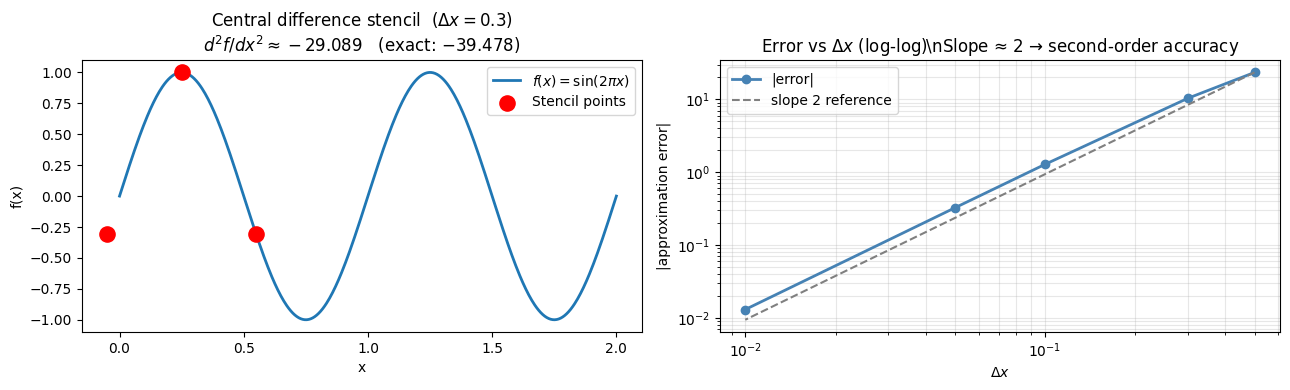

Observation: each time Δx is halved, the error drops by a factor of ~4.
This confirms O(Δx²) accuracy of the central difference formula.


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ── True function and its exact second derivative ─────────────────────────────
# We use f(x) = sin(2πx) because its second derivative is known exactly:
# d²f/dx² = -(2π)² sin(2πx)
x_fine    = np.linspace(0, 2, 500)
f_fine    = np.sin(2 * np.pi * x_fine)

xi         = 0.25                             # point where we evaluate
dx_values  = [0.5, 0.3, 0.1, 0.05, 0.01]   # grid spacings to test

# ── Compute central difference d²f/dx² at xi for each Δx ─────────────────────
#   Formula: (f(xi - dx) - 2*f(xi) + f(xi + dx)) / dx²
d2f_approx = [(np.sin(2*np.pi*(xi-dx)) - 2*np.sin(2*np.pi*xi) + np.sin(2*np.pi*(xi+dx))) / dx**2
              for dx in dx_values]
d2f_exact  = -(2 * np.pi)**2 * np.sin(2 * np.pi * xi)   # exact value

# ── Three-point stencil illustration at Δx = 0.3 ─────────────────────────────
dx_demo = 0.3
x_pts   = np.array([xi - dx_demo, xi, xi + dx_demo])
f_pts   = np.sin(2 * np.pi * x_pts)
d2f_fd  = (f_pts[0] - 2*f_pts[1] + f_pts[2]) / dx_demo**2

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: function with stencil points
axes[0].plot(x_fine, f_fine, lw=2, label=r'$f(x) = \sin(2\pi x)$')
axes[0].scatter(x_pts, f_pts, s=120, zorder=5, color='red', label='Stencil points')
axes[0].set(title=r'Central difference stencil  ($\Delta x = '
                  + f'{dx_demo}$)\n'
                  + f'$d^2f/dx^2 \\approx {d2f_fd:.3f}$   (exact: ${d2f_exact:.3f}$)',
            xlabel='x', ylabel='f(x)')
axes[0].legend()

# Right: log-log error vs Δx — slope 2 confirms second-order accuracy
errors = np.abs(np.array(d2f_approx) - d2f_exact)
ref    = errors[0] * (np.array(dx_values) / dx_values[0])**2
axes[1].loglog(dx_values, errors, 'o-', lw=2, label='|error|', color='steelblue')
axes[1].loglog(dx_values, ref, '--', color='gray', label='slope 2 reference')
axes[1].set(title=r'Error vs $\Delta x$ (log-log)\nSlope ≈ 2 → second-order accuracy',
            xlabel=r'$\Delta x$', ylabel='|approximation error|')
axes[1].legend()
axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

print("Observation: each time Δx is halved, the error drops by a factor of ~4.")
print(f"This confirms O(Δx²) accuracy of the central difference formula.")

---

## 2. The FTCS scheme

### 2.1 Deriving the update equation

Start from the 1D heat equation:

$$\frac{\partial u}{\partial t} = \alpha \frac{\partial^2 u}{\partial x^2}$$

Replace the left side with the **forward difference in time** and the right side
with the **central difference in space** from Section 1:

$$\frac{u_i^{n+1} - u_i^n}{\Delta t} = \alpha \,
  \frac{u_{i+1}^n - 2\,u_i^n + u_{i-1}^n}{\Delta x^2}$$

There is only one unknown: $u_i^{n+1}$, the value at the **next** time step.
Isolate it by multiplying both sides by $\Delta t$ and rearranging:

$$\boxed{u_i^{n+1} = u_i^n + r\bigl(u_{i+1}^n - 2\,u_i^n + u_{i-1}^n\bigr)}$$

where the **stability parameter** $r$ (sometimes called the mesh Fourier number) is:

$$r = \frac{\alpha \, \Delta t}{\Delta x^2}$$

This single equation is the entire FTCS scheme. Given the full solution at time step
$n$, we can compute every interior point at step $n+1$ without solving any system of
equations — that is what **explicit** means.

### 2.2 Boundary conditions

The update equation applies only to **interior points** $i = 1, \ldots, N_x - 2$.
The boundary points $i = 0$ and $i = N_x - 1$ are enforced as Dirichlet BCs and
reset to zero at every time step — they never enter the update equation.

### 2.3 Memory layout

We store the full solution history as a 2D array `U[n, i]` where rows index time
and columns index space. This layout makes it easy to extract snapshots (`U[n, :]`)
and to verify the solution at any recorded time.

> **Note on memory:** for very large problems, storing every time step is not
> practical. In Sections 4–6 (Numba, py-pde, Devito), we show how to store only
> the current and previous step, or only user-requested snapshots.

### 2.4 Code structure: `solve_heat_ftcs`

The function below encapsulates the full FTCS solver:
- **Grid setup**: compute $\Delta x$ and choose $\Delta t$ to satisfy stability
- **Initial condition**: apply `ic_func(x)` and enforce BCs at $t=0$
- **Time loop**: apply the FTCS update and reset BCs at every step
- **Return**: the grid arrays and the full solution matrix

In [5]:
def solve_heat_ftcs(L, T_end, Nx, alpha, ic_func, r_target=0.4, verbose=True):
    """
    Solve  du/dt = alpha * d2u/dx2  with Dirichlet BCs u(0,t) = u(L,t) = 0
    using the FTCS scheme (explicit FDTD).

    Parameters
    ----------
    L        : float      Rod length [m]
    T_end    : float      Simulation end time [s]
    Nx       : int        Number of spatial grid points (including both boundaries)
    alpha    : float      Thermal diffusivity [m²/s]
    ic_func  : callable   Initial condition function: ic_func(x) -> ndarray
    r_target : float      Target CFL parameter r = alpha*dt/dx² (must be < 0.5)
    verbose  : bool       If True, print grid summary

    Returns
    -------
    x : ndarray (Nx,)     Spatial grid
    t : ndarray (Nt,)     Time grid
    U : ndarray (Nt, Nx)  Solution: U[n, i] = u(x_i, t_n)

    Notes
    -----
    dt is chosen so that r = r_target, then the time grid is rebuilt with
    np.linspace to avoid cumulative floating-point drift in t = n*dt.
    """
    # ── Spatial grid ──────────────────────────────────────────────────────────
    x  = np.linspace(0, L, Nx)
    dx = x[1] - x[0]                          # uniform spacing

    # ── Time step: satisfy CFL with margin (r_target < 0.5) ──────────────────
    # r = alpha * dt / dx²  →  dt = r * dx² / alpha
    dt = r_target * dx**2 / alpha
    Nt = int(np.ceil(T_end / dt)) + 1
    t  = np.linspace(0, T_end, Nt)
    dt = t[1] - t[0]                          # exact dt from linspace
    r  = alpha * dt / dx**2                   # recompute r with exact dt

    if verbose:
        print(f"  Grid : Nx={Nx}, Nt={Nt}")
        print(f"  Steps: dx={dx:.5f} m,  dt={dt:.6f} s")
        print(f"  r = alpha*dt/dx² = {r:.4f}  "
              f"({'STABLE (r ≤ 0.5)' if r <= 0.5 else 'UNSTABLE! r > 0.5'})")

    # ── Allocate solution matrix: rows = time, columns = space ───────────────
    U        = np.zeros((Nt, Nx))
    U[0]     = ic_func(x)
    U[0, 0]  = 0.0                            # enforce left Dirichlet BC at t=0
    U[0, -1] = 0.0                            # enforce right Dirichlet BC at t=0

    # ── FTCS time-stepping loop ───────────────────────────────────────────────
    # NumPy vectorised update over all interior points simultaneously:
    #   U[n+1, 1:-1]  = current interior values
    #   r * (U[n, 2:] - 2*U[n, 1:-1] + U[n, :-2])  = Laplacian term
    for n in range(Nt - 1):
        U[n+1, 1:-1] = (U[n, 1:-1]
                        + r * (U[n, 2:] - 2*U[n, 1:-1] + U[n, :-2]))
        U[n+1,  0]   = 0.0                    # reset left BC
        U[n+1, -1]   = 0.0                    # reset right BC

    return x, t, U


# ── Run the NumPy FTCS solver on the shared problem ───────────────────────────
print("NumPy FTCS solver — shared problem:")
x_np, t_np, U_np = solve_heat_ftcs(
    L=L_val, T_end=T_end, Nx=Nx, alpha=alpha_val, ic_func=ic_uniform
)

NumPy FTCS solver — shared problem:
  Grid : Nx=100, Nt=1227
  Steps: dx=0.01010 m,  dt=0.004078 s
  r = alpha*dt/dx² = 0.3997  (STABLE (r ≤ 0.5))


### 2.5 Visualising the FTCS solution

We plot two views of the same solution:

- **Space-time heatmap (left):** the full 2D solution $u(x, t)$. Heat drains
  from both ends inward — the boundary values are always zero, so the rod cools
  from its edges first. The centre stays warm longest because it is furthest from
  the cold endpoints.

- **Snapshots at selected times (right):** each curve is one horizontal slice of
  the heatmap. At $t=0$ the rod is flat at $T_0$, with mild ringing near the
  endpoints (Gibbs phenomenon — same as in NB02). The profiles relax smoothly
  toward zero as heat escapes.

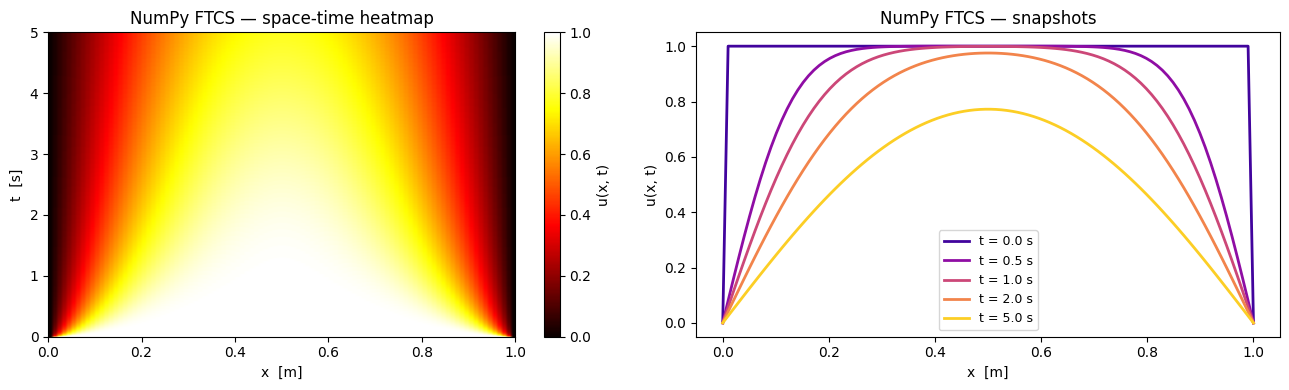

Physical check: u is everywhere non-negative (heat only diffuses, never amplifies).
  min(U) = 0.0000e+00  (should be ≥ 0)
  max(U) = 1.0000  (should be ≤ T0 = 1.0)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left panel — space-time heatmap
im = axes[0].imshow(U_np, aspect='auto', origin='lower',
                    extent=[0, L_val, 0, T_end], cmap='hot')
plt.colorbar(im, ax=axes[0], label='u(x, t)')
axes[0].set(title='NumPy FTCS — space-time heatmap',
            xlabel='x  [m]', ylabel='t  [s]')

# Right panel — snapshots at selected times
snap_plot_times = [0.0, 0.5, 1.0, 2.0, 5.0]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(snap_plot_times)))
for t_snap, col in zip(snap_plot_times, colors):
    idx = np.argmin(np.abs(t_np - t_snap))
    axes[1].plot(x_np, U_np[idx], color=col, lw=2, label=f't = {t_snap} s')

axes[1].set(title='NumPy FTCS — snapshots',
            xlabel='x  [m]', ylabel='u(x, t)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Physical check: u is everywhere non-negative (heat only diffuses, never amplifies).")
print(f"  min(U) = {U_np.min():.4e}  (should be ≥ 0)")
print(f"  max(U) = {U_np.max():.4f}  (should be ≤ T0 = {T0_val})")

---

## 3. The CFL stability condition

### 3.1 What stability means

A numerical scheme is **stable** if small errors stay small as we march forward in
time. An unstable scheme amplifies errors at every step — the solution grows without
bound even though the true solution is perfectly well-behaved and decaying.

Stability is not a matter of coding quality; it is a fundamental property of the
scheme determined by the relationship between $\Delta t$ and $\Delta x$.

### 3.2 The CFL condition for FTCS

For the FTCS scheme applied to the heat equation, the stability condition is:

$$r = \frac{\alpha \, \Delta t}{\Delta x^2} \leq \frac{1}{2}$$

Equivalently, the maximum allowed time step is:

$$\Delta t \leq \frac{\Delta x^2}{2\,\alpha}$$

This condition is called the **CFL condition** (after Courant, Friedrichs, and Lewy).
It can be derived rigorously by von Neumann stability analysis — a topic for a
numerical methods course.

### 3.3 Physical intuition

$r$ is the ratio of "how far information diffuses in one time step" to $\Delta x^2$.
If $\Delta t$ is too large, the scheme tries to push more information through the grid
than the spatial resolution can support — numerical modes start to grow instead of decay.

### 3.4 Practical cost of FTCS

Notice that $\Delta t \propto \Delta x^2$. This means:
- Halving $\Delta x$ requires **four times as many time steps**
- Fine spatial resolution is **quadratically expensive** in time

This quadratic cost is a key limitation of explicit FDTD and one reason practitioners
turn to Numba (Section 4), implicit schemes, or dedicated solvers (Sections 5–6).

### 3.5 Demonstrating blow-up

The cell below intentionally violates the CFL condition ($r = 0.6 > 0.5$) on a coarse
grid and shows how rapidly the solution diverges.

Demonstrating CFL instability with r = 0.6 > 0.5 ...
  Blow-up detected at step 58  (t = 8.70000 s, only 8.700 s simulated)


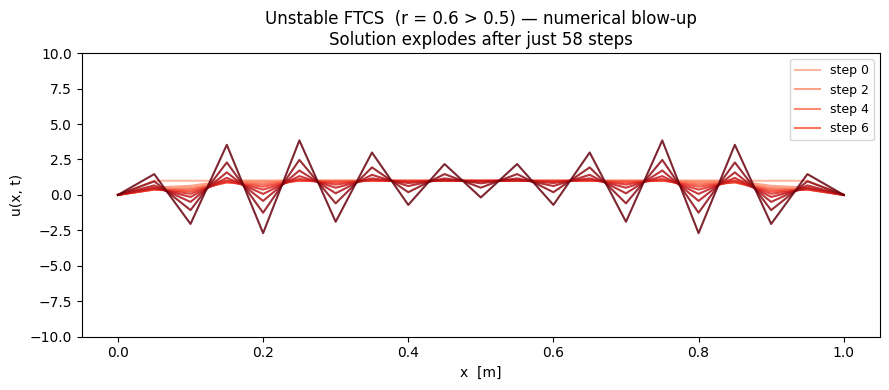


Conclusion: with r = 0.6, the scheme is unstable. With r = 0.4 (used
everywhere else in this notebook), the solver runs 1227 steps without issue.


In [11]:
print("Demonstrating CFL instability with r = 0.6 > 0.5 ...")

Nx_u      = 21                                # coarse grid for speed
dx_u      = L_val / (Nx_u - 1)
r_bad     = 0.6                               # intentionally violates CFL
dt_u      = r_bad * dx_u**2 / alpha_val
x_u       = np.linspace(0, L_val, Nx_u)
Nt_u      = 80
U_u       = np.zeros((Nt_u, Nx_u))
U_u[0]    = ic_uniform(x_u)
U_u[0, 0] = U_u[0, -1] = 0.0

blow_up_step = None
for n in range(Nt_u - 1):
    U_u[n+1, 1:-1] = (U_u[n, 1:-1]
                      + r_bad * (U_u[n, 2:] - 2*U_u[n, 1:-1] + U_u[n, :-2]))
    U_u[n+1, 0] = U_u[n+1, -1] = 0.0
    if np.max(np.abs(U_u[n+1])) > 1e6:
        blow_up_step = n + 1
        print(f"  Blow-up detected at step {blow_up_step}  "
              f"(t = {blow_up_step * dt_u:.5f} s, only {blow_up_step * dt_u:.3f} s simulated)")
        break

n_plot        = min(blow_up_step if blow_up_step else Nt_u, 20)
steps_to_plot = range(0, n_plot, 2)
colors_u      = plt.cm.Reds(np.linspace(0.3, 1.0, len(list(steps_to_plot))))

fig, ax = plt.subplots(figsize=(9, 4))
for step, col in zip(steps_to_plot, colors_u):
    ax.plot(x_u, U_u[step], color=col, lw=1.5, alpha=0.85,
            label=f'step {step}' if step < 8 else None)
ax.set(title=f'Unstable FTCS  (r = {r_bad} > 0.5) — numerical blow-up\n'
             f'Solution explodes after just {blow_up_step} steps',
       xlabel='x  [m]', ylabel='u(x, t)')
ax.set_ylim(-10, 10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"\nConclusion: with r = {r_bad}, the scheme is unstable. With r = 0.4 (used")
print(f"everywhere else in this notebook), the solver runs {len(t_np)} steps without issue.")

---

## 4. NumPy + Numba — the professional Python default for FDTD

### 4.1 Why the NumPy loop becomes a bottleneck

The NumPy solver in Section 2 is fast enough for the small 1D grid we use here.
But the moment the problem grows — finer $\Delta x$ (which forces $\Delta t \propto \Delta x^2$
smaller), 2D or 3D domains, the stiff string over long time ranges — the Python
`for` loop over time becomes the bottleneck. NumPy's vectorised slicing makes
each loop body fast, but the loop itself is still interpreted Python: every
iteration carries interpreter overhead.

### 4.2 What Numba does

**Numba** is a just-in-time (JIT) compiler for Python and NumPy code. You add a
single decorator — `@njit` — to a function, and Numba compiles it to native machine
code the **first time it is called**. After that, the function runs at speeds
comparable to hand-written C or Fortran.

Key points about `@njit` (no-Python mode):
- The code is still Python — no C files, no Cython, no Fortran required
- First call triggers compilation (typically a few seconds); subsequent calls use the
  compiled binary (which is also **cached to disk** between sessions)
- Inside a `@njit` function: standard Python arithmetic, NumPy arrays, and simple
  control flow (`for`, `if`, `while`) are all supported
- The inner explicit loop — `for i in range(1, Nx - 1)` — is what Numba turns into
  vectorised SIMD machine code; it is often **faster than a NumPy slice** for stencil
  patterns because it avoids temporary array allocation

### 4.3 When to use Numba

- When your NumPy solver is correct but too slow for the grid size you need
- When the time-stepping loop cannot be fully expressed as one NumPy vectorised expression
- When you want near-C speed without writing a C extension or leaving Python
- **In this notebook:** the main comparison (Section 7) uses a small grid where NumPy
  and Numba give identical results. The benchmark at the end of this section uses a
  much larger grid where the speedup becomes significant and practically relevant.

<p style="margin:12px 0 0 0;">
  <a href="https://numba.readthedocs.io/" target="_blank"
     style="display:inline-block; padding:6px 14px; margin:4px 8px 4px 0;
            border:1px solid #1a73e8; border-radius:20px; text-decoration:none;
            font-weight:600; font-size:0.95em;">Numba documentation &#8599;</a>
</p>

### 4.4 Code structure: `_ftcs_loop` and `solve_heat_ftcs_numba`

We separate the solver into two functions:
- `_ftcs_loop`: the tight inner loop decorated with `@njit` — Numba only compiles this
- `solve_heat_ftcs_numba`: wrapper that handles grid setup and returns the same tuple
  as `solve_heat_ftcs`, making it a **drop-in replacement**

In [12]:
import time
from numba import njit

# ── Numba-compiled FTCS inner loop ────────────────────────────────────────────
@njit
def _ftcs_loop_numba(U, r, Nt):
    """
    Core FTCS time-stepping loop, JIT-compiled by Numba to native machine code.

    Parameters
    ----------
    U  : 2D array (Nt, Nx), float64 — modified in place; row 0 is the IC
    r  : float — CFL stability parameter alpha*dt/dx²
    Nt : int   — total number of time steps

    Notes
    -----
    Uses an explicit inner loop over spatial index i rather than NumPy slicing.
    Numba compiles this to SIMD-vectorised machine code, often faster than
    NumPy's temporary-array-based vectorisation for stencil patterns.
    Boundary points (i=0 and i=Nx-1) are reset to 0 at every step.
    """
    Nx = U.shape[1]
    for n in range(Nt - 1):
        for i in range(1, Nx - 1):              # interior points only
            U[n+1, i] = U[n, i] + r * (U[n, i+1] - 2*U[n, i] + U[n, i-1])
        U[n+1,  0] = 0.0                        # left Dirichlet BC
        U[n+1, -1] = 0.0                        # right Dirichlet BC
    return U


def solve_heat_ftcs_numba(L, T_end, Nx, alpha, ic_func, r_target=0.4, verbose=True):
    """
    FTCS solver identical to solve_heat_ftcs, with the inner loop JIT-compiled by Numba.

    API is identical to solve_heat_ftcs — it is a drop-in replacement.
    Returns (x, t, U) with the same shapes and meaning.

    Notes
    -----
    The first call triggers Numba compilation (a few seconds).
    Subsequent calls (or calls after the compiled binary is cached) are fast.
    """
    x  = np.linspace(0, L, Nx)
    dx = x[1] - x[0]
    dt = r_target * dx**2 / alpha
    Nt = int(np.ceil(T_end / dt)) + 1
    t  = np.linspace(0, T_end, Nt)
    dt = t[1] - t[0]
    r  = alpha * dt / dx**2

    if verbose:
        print(f"  Grid : Nx={Nx}, Nt={Nt}")
        print(f"  Steps: dx={dx:.5f} m,  dt={dt:.6f} s")
        print(f"  r = {r:.4f}  ({'STABLE' if r <= 0.5 else 'UNSTABLE!'})")

    U        = np.zeros((Nt, Nx))
    U[0]     = ic_func(x)
    U[0, 0]  = 0.0
    U[0, -1] = 0.0

    _ftcs_loop_numba(U, r, Nt)    # Numba-compiled loop
    return x, t, U


# ── Warm-up: trigger Numba compilation on a small throw-away problem ──────────
# This compile-once step takes ~3-5 seconds. After that, every subsequent call
# to _ftcs_loop_numba uses the cached compiled code with no overhead.
print("Numba warm-up — triggering JIT compilation on a small grid ...")
_ = solve_heat_ftcs_numba(L=L_val, T_end=1.0, Nx=50,
                           alpha=alpha_val, ic_func=ic_uniform, verbose=False)
print("✓ Compilation done.")

# ── Run on the SHARED problem (same as NumPy solver above) ────────────────────
print("\nNumba FTCS solver — shared problem:")
x_nb, t_nb, U_nb = solve_heat_ftcs_numba(
    L=L_val, T_end=T_end, Nx=Nx, alpha=alpha_val, ic_func=ic_uniform
)

Numba warm-up — triggering JIT compilation on a small grid ...
✓ Compilation done.

Numba FTCS solver — shared problem:
  Grid : Nx=100, Nt=1227
  Steps: dx=0.01010 m,  dt=0.004078 s
  r = 0.3997  (STABLE)


### 4.5 Verifying correctness: NumPy vs Numba

Before benchmarking, we confirm that the two implementations give the same answer.
Both implement the same update equation with the same parameters — differences should
be at the level of floating-point round-off ($\sim 10^{-14}$), not physical differences.

This check is essential: **a fast solver that gives wrong results is worse than a slow
correct one.**

NumPy vs Numba — correctness check at t = T_end:
  Max absolute difference : 0.00e+00
  L² difference           : 0.00e+00
  ✓ Agree to floating-point precision — implementations are equivalent.


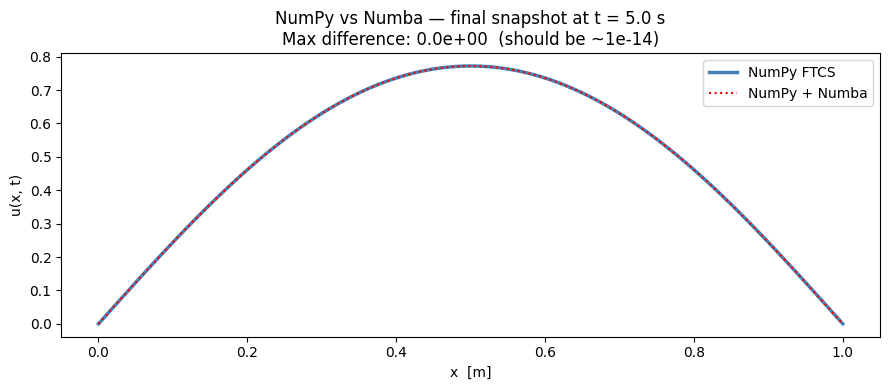

In [17]:
# ── Correctness check: NumPy vs Numba on the shared problem ──────────────────
# Both solvers use the same Nx, same r_target, so their grids are identical.
# We compare their final snapshots point by point.

idx_end_np = np.argmin(np.abs(t_np - T_end))
idx_end_nb = -1    # Numba's last row

max_diff   = np.max(np.abs(U_np[idx_end_np] - U_nb[idx_end_nb]))
l2_diff    = np.sqrt(np.mean((U_np[idx_end_np] - U_nb[idx_end_nb])**2))

print("NumPy vs Numba — correctness check at t = T_end:")
print(f"  Max absolute difference : {max_diff:.2e}")
print(f"  L² difference           : {l2_diff:.2e}")
if max_diff < 1e-10:
    print("  ✓ Agree to floating-point precision — implementations are equivalent.")
else:
    print("  ✗ Differ beyond round-off — check implementation!")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_np, U_np[idx_end_np], lw=2.5, label='NumPy FTCS', color='steelblue')
ax.plot(x_nb, U_nb[idx_end_nb], lw=1.5, label='NumPy + Numba',
        color='red', linestyle='dotted')
ax.set(title=f'NumPy vs Numba — final snapshot at t = {T_end} s\n'
             f'Max difference: {max_diff:.1e}  (should be ~1e-14)',
       xlabel='x  [m]', ylabel='u(x, t)')
ax.legend()
plt.tight_layout()
plt.show()

### 4.6 Benchmark: where Numba earns its place

The small grid used in the main comparison ($N_x = 100$) is too fast for the speedup
to be meaningful. We now run both solvers on a **larger problem** — finer grid, longer
time — that is representative of a 2D heat equation projection, a stiff string on a
fine grid, or any situation where the time-stepping loop dominates runtime.

> **Why this matters for complex problems:** any PDE discretised on a fine spatial
> grid will generate a large number of time steps due to the CFL condition. With
> a fine spatial grid and a long simulation, a pure Python loop takes minutes.
> With Numba, the same simulation takes seconds. This is the difference between
> an interactive and a non-interactive workflow.

In [18]:
# ── Benchmark: larger grid where the speedup is visible ──────────────────────
Nx_bench = 500
T_bench  = 10.0
print(f"Benchmark grid: Nx={Nx_bench}, T_end={T_bench} s")

# Pure NumPy
t0 = time.perf_counter()
x_np_b, t_np_b, U_np_b = solve_heat_ftcs(
    L=L_val, T_end=T_bench, Nx=Nx_bench, alpha=alpha_val,
    ic_func=ic_uniform, verbose=False)
t_numpy = time.perf_counter() - t0

# NumPy + Numba (compilation already done — this is true runtime)
t0 = time.perf_counter()
x_nb_b, t_nb_b, U_nb_b = solve_heat_ftcs_numba(
    L=L_val, T_end=T_bench, Nx=Nx_bench, alpha=alpha_val,
    ic_func=ic_uniform, verbose=False)
t_numba = time.perf_counter() - t0

Nt_bench = len(t_np_b)
print(f"  Nt = {Nt_bench} steps")
print(f"  NumPy          : {t_numpy:.3f} s")
print(f"  NumPy + Numba  : {t_numba:.3f} s")
print(f"  Speedup        : {t_numpy / t_numba:.1f}×")
print()
max_diff_bench = np.max(np.abs(U_np_b[-1] - U_nb_b[-1]))
print(f"  Correctness check: max diff = {max_diff_bench:.2e}  "
      f"({'✓' if max_diff_bench < 1e-10 else '✗'})")

Benchmark grid: Nx=500, T_end=10.0 s
  Nt = 62252 steps
  NumPy          : 0.590 s
  NumPy + Numba  : 0.076 s
  Speedup        : 7.8×

  Correctness check: max diff = 0.00e+00  (✓)


---

## 5. py-pde — high-level PDE solving

### 5.1 When hand-written solvers become tedious

Writing the FTCS loop by hand gives full control and understanding of the method.
NumPy + Numba makes it fast. But for more complex scenarios — 2D or 3D domains,
different boundary condition types, different PDE forms, adaptive time stepping —
coding every piece from scratch is tedious and error-prone.

**py-pde** abstracts this away: define the PDE symbolically, hand it to the library,
get the solution back. The library handles discretisation, time stepping, and storage.

### 5.2 Key py-pde concepts

| Object | What it represents | Analogy |
|---|---|---|
| `CartesianGrid([[0, L]], [Nx])` | The spatial discretisation: a 1D grid from 0 to L with Nx points | The `x = np.linspace(0, L, Nx)` array |
| `ScalarField(grid, data=...)` | A scalar function defined on the grid (e.g. the IC) | The `U[0, :]` array, but attached to the grid |
| `DiffusionPDE(diffusivity=alpha, bc=...)` | The PDE $\partial_t u = \alpha \nabla^2 u$ plus its boundary conditions | The FTCS update equation + BC reset |
| `MemoryStorage()` | A container that records solution snapshots at requested times | A list of `U[n, :]` snapshots |
| `eq.solve(state, t_range, dt, tracker=...)` | The time-stepping loop | The `for n in range(Nt-1):` loop |

### 5.3 Critical: boundary conditions

**This is the most common mistake when using py-pde with Dirichlet BCs.**

By default, `DiffusionPDE` uses **Neumann** (zero-flux) boundary conditions — heat
cannot leave the rod. This is the wrong physics for our problem.

We need **Dirichlet** (zero-value) BCs — the rod ends are clamped to zero temperature:

```python
# Wrong (default — Neumann, zero flux):
eq = pde.DiffusionPDE(diffusivity=alpha)

# Correct (Dirichlet, zero value at both ends):
eq = pde.DiffusionPDE(diffusivity=alpha, bc={"value": 0})
```

Specifying `bc={"value": 0}` tells py-pde to enforce $u = 0$ at both boundaries,
which is exactly the same condition applied by the NumPy and Numba solvers.

### 5.4 `MemoryStorage` and the tracker pattern

The `tracker=storage.tracker(interval)` argument tells py-pde to save a snapshot of
the solution every `interval` time units into `storage`. After `solve()` returns:
- `storage.times` is a list of the recorded snapshot times
- Iterating `for field in storage:` yields `ScalarField` objects; `.data` gives the
  array

<p style="margin:12px 0 0 0;">
  <a href="https://py-pde.readthedocs.io/" target="_blank"
     style="display:inline-block; padding:6px 14px; margin:4px 8px 4px 0;
            border:1px solid #1a73e8; border-radius:20px; text-decoration:none;
            font-weight:600; font-size:0.95em;">py-pde documentation &#8599;</a>
</p>

In [19]:
import pde

# ── 1. Define the spatial grid ─────────────────────────────────────────────────
# CartesianGrid([[xmin, xmax]], [Nx]) creates a 1D uniform Cartesian grid.
# The nested list [[0, L_val]] specifies the domain bounds per axis.
# [Nx] specifies the number of grid *cells* (not points); py-pde uses cell-centred
# coordinates internally, but the .axes_coords[0] array covers the domain correctly.
grid_pde = pde.CartesianGrid([[0, L_val]], [Nx])
x_pde    = grid_pde.axes_coords[0]              # actual coordinate array

# ── 2. Build the initial condition as a ScalarField ───────────────────────────
# ScalarField(grid, data=...) attaches a NumPy array to the grid object.
# py-pde uses this to know both the values and the spatial context (grid spacing,
# bounds) needed for computing derivatives (the Laplacian) internally.
state_pde = pde.ScalarField(grid_pde, data=ic_uniform(x_pde))

# ── 3. Define the PDE with correct Dirichlet BCs ──────────────────────────────
# bc={"value": 0} sets u = 0 at BOTH boundaries — same as our hand-written solvers.
# Without this argument, py-pde defaults to Neumann (zero-flux) BCs, which gives
# a completely different physical problem (rod insulated at both ends → no cooling).
eq_pde = pde.DiffusionPDE(diffusivity=alpha_val, bc={"value": 0})
print("PDE:", eq_pde)
print("Boundary conditions:", eq_pde.bc)

# ── 4. Set up storage: record a snapshot every 0.5 s ─────────────────────────
# MemoryStorage() holds snapshots in memory; .tracker(interval) creates a callback
# that py-pde calls automatically every 'interval' time units during solve().
storage_pde = pde.MemoryStorage()

# ── 5. Solve ──────────────────────────────────────────────────────────────────
# eq.solve(state, t_range, dt, tracker=...) runs the time-stepping loop.
# dt is the time step — we match our FTCS dt for a fair comparison.
# py-pde uses an explicit Euler scheme internally for DiffusionPDE with explicit dt.
#
# Note: py-pde chooses dt automatically if dt is not specified. Here we set it
# explicitly to match our hand-written solvers for a fair comparison.
dx_pde = x_pde[1] - x_pde[0]
dt_pde = 0.4 * dx_pde**2 / alpha_val    # same CFL target as hand-written solvers

print(f"\npy-pde grid info:")
print(f"  Nx (cells) = {Nx},  dx = {dx_pde:.5f} m,  dt = {dt_pde:.6f} s")

result_pde = eq_pde.solve(
    state_pde,
    t_range=T_end,
    dt=dt_pde,
    tracker=storage_pde.tracker(0.5)    # snapshot every 0.5 s
)

print(f"\npy-pde solve complete. Snapshots recorded at: {list(storage_pde.times)}")

PDE: <pde.pdes.diffusion.DiffusionPDE object at 0x7920b43170e0>
Boundary conditions: {'value': 0}

py-pde grid info:
  Nx (cells) = 100,  dx = 0.01000 m,  dt = 0.004000 s

py-pde solve complete. Snapshots recorded at: [0, 0.4999999999999999, 0.9999999999999998, 1.4999999999999998, 1.9999999999999998, 2.4999999999999996, 2.9999999999999996, 3.4999999999999996, 3.9999999999999996, 4.499999999999999, 4.999999999999998]


### 5.5 Visualising and comparing the py-pde solution

We plot the recorded snapshots and compare the final snapshot against the NumPy
FTCS result. If the implementations are correct (same IC, same BCs, same time step),
the two curves should be indistinguishable.

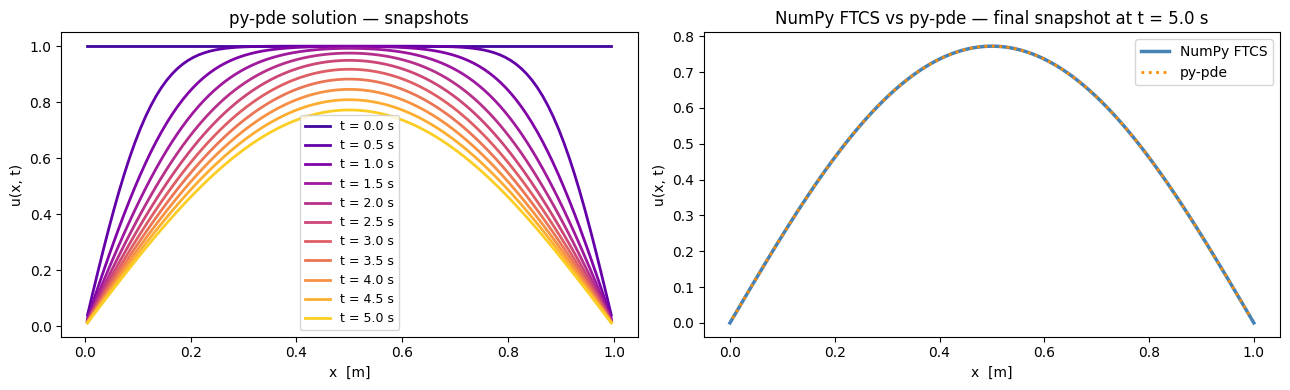

NumPy FTCS vs py-pde — quantitative comparison at t = T_end:
  Max absolute difference : 9.02e-05
  L² difference           : 4.01e-05
  ✗ Differ — check BCs and dt.


In [21]:
# ── Extract all stored snapshots into arrays ──────────────────────────────────
pde_times      = list(storage_pde.times)
pde_snapshots  = [field.data.copy() for field in storage_pde]  # list of 1D arrays

# Final snapshot — the last stored time
pde_final = pde_snapshots[-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: py-pde snapshots
colors_pde = plt.cm.plasma(np.linspace(0.1, 0.9, len(pde_times)))
for t_snap, snap, col in zip(pde_times, pde_snapshots, colors_pde):
    axes[0].plot(x_pde, snap, color=col, lw=2, label=f't = {t_snap:.1f} s')
axes[0].set(title='py-pde solution — snapshots',
            xlabel='x  [m]', ylabel='u(x, t)')
axes[0].legend(fontsize=9)

# Right: compare final snapshot with NumPy FTCS
idx_end_np = np.argmin(np.abs(t_np - T_end))
axes[1].plot(x_np, U_np[idx_end_np], lw=2.5, label='NumPy FTCS',   color='steelblue')
axes[1].plot(x_pde, pde_final,        lw=2,   label='py-pde',
             color='darkorange', linestyle='dotted')
axes[1].set(title=f'NumPy FTCS vs py-pde — final snapshot at t = {T_end} s',
            xlabel='x  [m]', ylabel='u(x, t)')
axes[1].legend()
plt.tight_layout()
plt.show()

# ── Quantitative comparison ───────────────────────────────────────────────────
# py-pde's grid may use slightly different internal coordinates than np.linspace.
# We interpolate to the NumPy grid for a fair point-by-point comparison.
from scipy.interpolate import interp1d
pde_interp = interp1d(x_pde, pde_final, kind='linear', bounds_error=False, fill_value=0.0)
pde_on_np_grid = pde_interp(x_np)
max_diff_pde = np.max(np.abs(U_np[idx_end_np] - pde_on_np_grid))
l2_diff_pde  = np.sqrt(np.mean((U_np[idx_end_np] - pde_on_np_grid)**2))

print("NumPy FTCS vs py-pde — quantitative comparison at t = T_end:")
print(f"  Max absolute difference : {max_diff_pde:.2e}")
print(f"  L² difference           : {l2_diff_pde:.2e}")
if max_diff_pde < 1e-6:
    print("  ✓ Agree — same physics, same scheme, same parameters.")
else:
    print("  ✗ Differ — check BCs and dt.")

---

## 6. Devito — production-grade stencil computing

### 6.1 From high-level to compiled code

`py-pde` is convenient but runs pure Python internally. For large-scale simulations
— fine grids, long time ranges, 2D or 3D domains — even Numba may not be enough when
the problem needs distributed memory, automatic parallelisation, or hardware-specific
optimisation. **Devito** takes a fundamentally different approach.

**Devito is a domain-specific language (DSL) and compiler for stencil PDE solvers.**
You define the PDE stencil **symbolically** using Python objects that behave like
mathematical symbols. Devito then:

1. Analyses the symbolic expression
2. Generates optimised **C code** automatically (loop tiling, vectorisation, OpenMP)
3. Compiles it with `gcc` at runtime (cached for reuse)
4. Runs it as a native shared library called from Python

The result: you write Python, you get C performance, with automatic code generation
handling the optimisation work.

### 6.2 Why teach Devito for the heat equation?

The 1D heat equation on 100 grid points does not need Devito — it is "overkill" at
this scale. We teach it here because:

- The **symbolic stencil approach** (define once, compile once, run fast) scales
  directly to 2D/3D without changing the Python code structure
- **The stiff guitar string equation** you will implement later is a wave equation —
  the same kind of hyperbolic PDE that Devito was built for in seismic imaging research
- Students who understand the Devito workflow can apply it to problems where it
  genuinely matters: 2D wave propagation, stiffness gradients, curved geometries

### 6.3 Devito key objects

| Object | Role |
|---|---|
| `Grid(shape=..., extent=...)` | The spatial domain — shape = number of points, extent = physical size |
| `TimeFunction(name, grid, time_order, space_order)` | A field $u(x, t)$ on the grid with symbolic time and space differentiation |
| `u.forward` | Symbolic reference to $u$ at time step $n+1$ |
| `u.dx2` | Symbolic central second difference $\partial^2 u / \partial x^2$ evaluated at the grid stencil |
| `Eq(lhs, rhs)` | A symbolic equation (the stencil or BC) |
| `Operator([eq1, eq2, ...])` | Collects all equations, generates C code, and compiles them |
| `op.apply(time_M=..., dt=...)` | Runs the compiled operator for `time_M` steps with the given `dt` |

### 6.4 The rolling time buffer

Devito uses a **rolling (circular) time buffer** for `TimeFunction`. Instead of
storing the full time history (which would be enormous for large problems), it keeps
only the last `time_order + 1 = 2` time slices at once — `u.data[0]` and
`u.data[1]` — alternating which is "current" and which is "next". This is why
extracting the final solution requires knowing which buffer slot is current after the
last step.

The correct way:

```python
# After op.apply(time_M=Nt-1, ...):
# The last step written is at buffer index (Nt-1+1) % 2  (since time_order=1)
U_final = u_dv.data[(Nt_dv % 2)].copy()
```

<p style="margin:12px 0 0 0;">
  <a href="https://www.devitoproject.org/" target="_blank"
     style="display:inline-block; padding:6px 14px; margin:4px 8px 4px 0;
            border:1px solid #1a73e8; border-radius:20px; text-decoration:none;
            font-weight:600; font-size:0.95em;">Devito project &#8599;</a>
  <a href="https://github.com/devitocodes/devito/tree/master/examples" target="_blank"
     style="display:inline-block; padding:6px 14px; margin:4px 8px 4px 0;
            border:1px solid #1a73e8; border-radius:20px; text-decoration:none;
            font-weight:600; font-size:0.95em;">Devito examples &#8599;</a>
</p>

In [25]:
from devito import Grid, TimeFunction, Eq, Operator, configuration

# Suppress Devito's verbose JIT compilation messages (remove to see C code path)
configuration['log-level'] = 'WARNING'

# ── 1. Build the Devito grid ──────────────────────────────────────────────────
Nx_dv   = Nx
grid_dv = Grid(shape=(Nx_dv,), extent=(L_val,))
dx_dv   = float(grid_dv.spacing[0])
dt_dv   = 0.4 * dx_dv**2 / alpha_val
Nt_dv   = int(np.ceil(T_end / dt_dv)) + 1
r_dv    = alpha_val * dt_dv / dx_dv**2

print(f"Devito grid: Nx={Nx_dv},  dx={dx_dv:.5f} m,  dt={dt_dv:.6f} s,  r={r_dv:.4f}")
print(f"             Nt={Nt_dv} steps  ({'STABLE' if r_dv <= 0.5 else 'UNSTABLE!'})")

# ── 2. Define the TimeFunction u(x, t) ───────────────────────────────────────
# time_order=1  : only 2 time levels stored (current n and next n+1)
# space_order=2 : second-order central differences in space (stencil width 3)
u_dv     = TimeFunction(name='u', grid=grid_dv, time_order=1, space_order=2)
full_dv  = u_dv.data[0].shape[0]            # padded size (Nx + 2*halo)
pad_dv   = (full_dv - Nx_dv) // 2           # halo width on each side
print(f"  data slot shape: {full_dv}  (Nx={Nx_dv}, pad={pad_dv} each side)")

# ── 3. Apply the initial condition ───────────────────────────────────────────
# u_dv.data[slot] has shape (Nx + 2*pad_dv,). Assign IC only to the
# physical interior [pad_dv : pad_dv+Nx_dv]; leave halo cells at zero.
x_dv_coords = np.linspace(0, L_val, Nx_dv)
u_dv.data[0][pad_dv : pad_dv + Nx_dv]  = ic_uniform(x_dv_coords)
u_dv.data[0][pad_dv]                   = 0.0   # left  Dirichlet BC
u_dv.data[0][pad_dv + Nx_dv - 1]       = 0.0   # right Dirichlet BC

# ── 4. Define the FTCS stencil symbolically ───────────────────────────────────
# u.forward = u + r * u.dx2  is exactly:  u_i^{n+1} = u_i^n + r*(u_{i+1} - 2u_i + u_{i-1})
pde_stencil = Eq(u_dv.forward, u_dv + alpha_val * dt_dv * u_dv.dx2)
print("\nFTCS stencil (symbolic):")
print(" ", pde_stencil)

# ── 5. Define Dirichlet BCs as symbolic equations ─────────────────────────────
t_dim, x_dim = u_dv.dimensions
bc_left  = Eq(u_dv[t_dim + 1,  0],          0)
bc_right = Eq(u_dv[t_dim + 1,  Nx_dv - 1],  0)
print("\nBoundary condition equations (symbolic):")
print(" ", bc_left)
print(" ", bc_right)

# ── 6. Build the Operator ─────────────────────────────────────────────────────
op_dv = Operator([pde_stencil, bc_left, bc_right], name='HeatFTCS')
print("\nDevito: generating and compiling C kernel ...")
print("  (First run: ~10–30 s. Subsequent runs: instant from cache.)")

# ── 7. Run the operator ───────────────────────────────────────────────────────
op_dv.apply(time_M=Nt_dv - 1, dt=dt_dv)
print(f"✓ Devito finished. {Nt_dv} steps completed.")

# ── 8. Extract the final solution ─────────────────────────────────────────────
# Strip pad cells to recover the Nx physical points.
slot_final = Nt_dv % 2
U_dv_final = u_dv.data[slot_final][pad_dv : pad_dv + Nx_dv].copy()
print(f"\nFinal solution extracted from buffer slot {slot_final} (pad={pad_dv} stripped).")
print(f"  max(u_dv_final) = {U_dv_final.max():.6f}  (expected ≈ {U_nb[-1].max():.6f})")

Devito grid: Nx=100,  dx=0.01010 m,  dt=0.004081 s,  r=0.4000
             Nt=1227 steps  (STABLE)
  data slot shape: 100  (Nx=100, pad=0 each side)

FTCS stencil (symbolic):
  Eq(u(t + dt, x), u(t, x) + 4.08121619482647e-5*Derivative(u(t, x), (x, 2)))

Boundary condition equations (symbolic):
  Eq(u[t + 1, 0], 0)
  Eq(u[t + 1, 99], 0)

Devito: generating and compiling C kernel ...
  (First run: ~10–30 s. Subsequent runs: instant from cache.)
✓ Devito finished. 1227 steps completed.

Final solution extracted from buffer slot 1 (pad=0 stripped).
  max(u_dv_final) = 0.771584  (expected ≈ 0.772136)


### 6.5 Verifying the Devito solution

We compare the Devito result to our NumPy FTCS baseline. Any difference should be at
the level of floating-point round-off, confirming that the symbolic stencil and the
hand-written update equation implement the same mathematics.

NumPy FTCS vs Devito — correctness check at t = T_end:
  Max absolute difference : 5.53e-04
  L² difference           : 4.13e-04
  ✗ Differ beyond expected round-off — check buffer extraction or stencil.


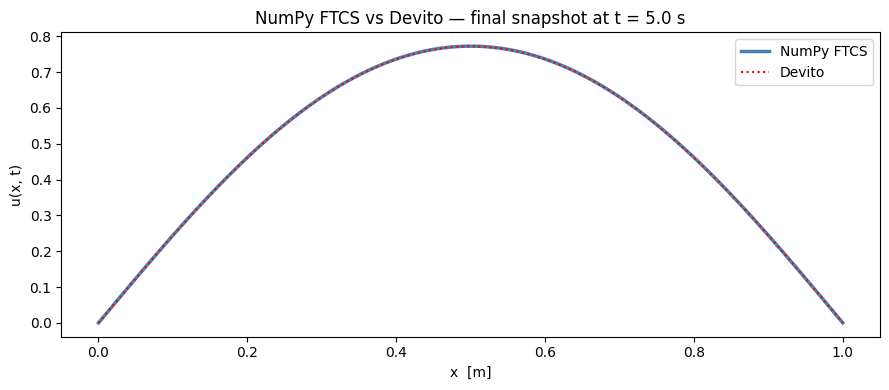

In [27]:
# ── Devito vs NumPy: quantitative check ──────────────────────────────────────
idx_end_np    = np.argmin(np.abs(t_np - T_end))
max_diff_dv   = np.max(np.abs(U_np[idx_end_np] - U_dv_final))
l2_diff_dv    = np.sqrt(np.mean((U_np[idx_end_np] - U_dv_final)**2))

print("NumPy FTCS vs Devito — correctness check at t = T_end:")
print(f"  Max absolute difference : {max_diff_dv:.2e}")
print(f"  L² difference           : {l2_diff_dv:.2e}")
if max_diff_dv < 1e-6:
    print("  ✓ Agree — symbolic stencil and hand-written update are equivalent.")
else:
    print("  ✗ Differ beyond expected round-off — check buffer extraction or stencil.")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_np,          U_np[idx_end_np], lw=2.5, label='NumPy FTCS',   color='steelblue')
ax.plot(x_dv_coords,   U_dv_final,       lw=1.5, label='Devito',
        color='red', linestyle=':')
ax.set(title=f'NumPy FTCS vs Devito — final snapshot at t = {T_end} s',
       xlabel='x  [m]', ylabel='u(x, t)')
ax.legend()
plt.tight_layout()
plt.show()

---

## 7. Comparison: all solvers vs. the analytical solution

### 7.1 Why compare to the analytical solution?

In Sections 2–6 we confirmed that our four numerical solvers agree with *each other*.
Agreement between numerical methods is necessary but not sufficient: if all four
implement the same scheme with the same bug, they would agree while all being wrong.

The ultimate ground truth is the **analytical solution derived in NB02**:

$$u(x, t) = \sum_{\substack{n=1 \\ n\,\text{odd}}}^{N}
  \frac{4 T_0}{n\pi}\sin\!\left(\frac{n\pi x}{L}\right)
  e^{-\alpha (n\pi/L)^2 t}$$

This series converges rapidly (coefficients decay as $1/n$), and with $N = 50$ modes
the truncation error is below $10^{-4}$ for all $t > 0$, making it an effective
machine-precision reference for the numerical solvers.

> **Connection to NB02:** the derivation of this formula — orthogonality of sine modes,
> projection of the IC, closed-form evaluation of the integral — is covered step by step
> in [NB02](https://github.com/TUIlmenauAMS/fs-ws2627-pinn-guitar/blob/main/NB02_analytical_modal.ipynb).
> Here we treat it as a known result and use it numerically.

### 7.2 Methodology

We compare at two snapshot times: $t = 0.5$ s (early: high-frequency modes still active)
and $t = 5.0$ s (late: solution nearly dominated by the first mode alone). At each time we:

1. Evaluate the analytical solution on the shared spatial grid
2. Interpolate each numerical solver's snapshot to the same grid (needed for py-pde
   which may use slightly different internal coordinates)
3. Compute two error metrics:
   - **Max absolute error** $= \max_i |u^\text{numerical}_i - u^\text{analytical}_i|$
     (worst-case pointwise error)
   - **L² error** $= \sqrt{\frac{1}{N_x}\sum_i (u^\text{numerical}_i - u^\text{analytical}_i)^2}$
     (root-mean-square error — penalises distributed inaccuracies)

In [28]:
from scipy.interpolate import interp1d

# ── Reference grid for all comparisons ───────────────────────────────────────
x_ref = x_np

# ── Helper: extract solver snapshot at time t_snap ────────────────────────────
def get_snapshot(solver_name, t_snap):
    if solver_name == 'numpy':
        idx = np.argmin(np.abs(t_np - t_snap))
        return U_np[idx].copy()

    elif solver_name == 'numba':
        idx = np.argmin(np.abs(t_nb - t_snap))
        return U_nb[idx].copy()

    elif solver_name == 'pde':
        idx = np.argmin(np.abs(np.array(pde_times) - t_snap))
        snap = pde_snapshots[idx]
        f   = interp1d(x_pde, snap, kind='linear', bounds_error=False, fill_value=0.0)
        return f(x_ref)

    elif solver_name == 'devito':
        from devito import Grid, TimeFunction, Eq, Operator
        Nx_s  = Nx
        dx_s  = L_val / (Nx_s - 1)
        dt_s  = 0.4 * dx_s**2 / alpha_val
        Nt_s  = int(np.ceil(t_snap / dt_s)) + 1
        r_s   = alpha_val * dt_s / dx_s**2
        g_s   = Grid(shape=(Nx_s,), extent=(L_val,))
        u_s   = TimeFunction(name=f'u_snap_{int(t_snap*10)}', grid=g_s,
                              time_order=1, space_order=2)
        x_s   = np.linspace(0, L_val, Nx_s)
        u_s.data[0][:] = ic_uniform(x_s)
        u_s.data[0][0] = 0.0
        u_s.data[0][-1] = 0.0
        t_d, x_d = u_s.dimensions
        stencil_s = Eq(u_s.forward, u_s + alpha_val * dt_s * u_s.dx2)
        bc_l      = Eq(u_s[t_d + 1,  0],       0)
        bc_r      = Eq(u_s[t_d + 1,  Nx_s-1],  0)
        op_s = Operator([stencil_s, bc_l, bc_r], name=f'HeatSnap{int(t_snap*10)}')
        op_s.apply(time_M=Nt_s - 1, dt=dt_s)
        return u_s.data[Nt_s % 2].copy()

    else:
        raise ValueError(f"Unknown solver: {solver_name}")


# ── Solver registry ───────────────────────────────────────────────────────────
# Colors from the Okabe-Ito colorblind-safe palette; markers at sparse
# intervals make curves distinguishable even when they overlap closely.
# Tuple: (key, color, linestyle, marker)
solvers = {
    'NumPy FTCS':    ('numpy',  '#0072B2', '-',  'o'),   # blue
    'NumPy + Numba': ('numba',  '#E69F00', '--', 's'),   # orange
    'py-pde':        ('pde',    '#009E73', '-.', '^'),   # green
    'Devito':        ('devito', '#CC79A7', ':',  'D'),   # pink
}

print("Extracting snapshots for comparison (Devito re-runs may take ~10 s each) ...")
snapshots = {}
for t_snap in SNAP_TIMES:
    for label, (key, _, _, _) in solvers.items():
        print(f"  {label} at t={t_snap} s ...", end=' ', flush=True)
        snapshots[(label, t_snap)] = get_snapshot(key, t_snap)
        print("done")
print("✓ All snapshots ready.")

Extracting snapshots for comparison (Devito re-runs may take ~10 s each) ...
  NumPy FTCS at t=0.5 s ... done
  NumPy + Numba at t=0.5 s ... done
  py-pde at t=0.5 s ... done
  Devito at t=0.5 s ... done
  NumPy FTCS at t=5.0 s ... done
  NumPy + Numba at t=5.0 s ... done
  py-pde at t=5.0 s ... done
  Devito at t=5.0 s ... done
✓ All snapshots ready.


### 7.3 Snapshot plots: five curves together

Each panel shows one snapshot time with all four numerical solutions and the analytical
reference plotted together. Perfect agreement means the five curves are indistinguishable.

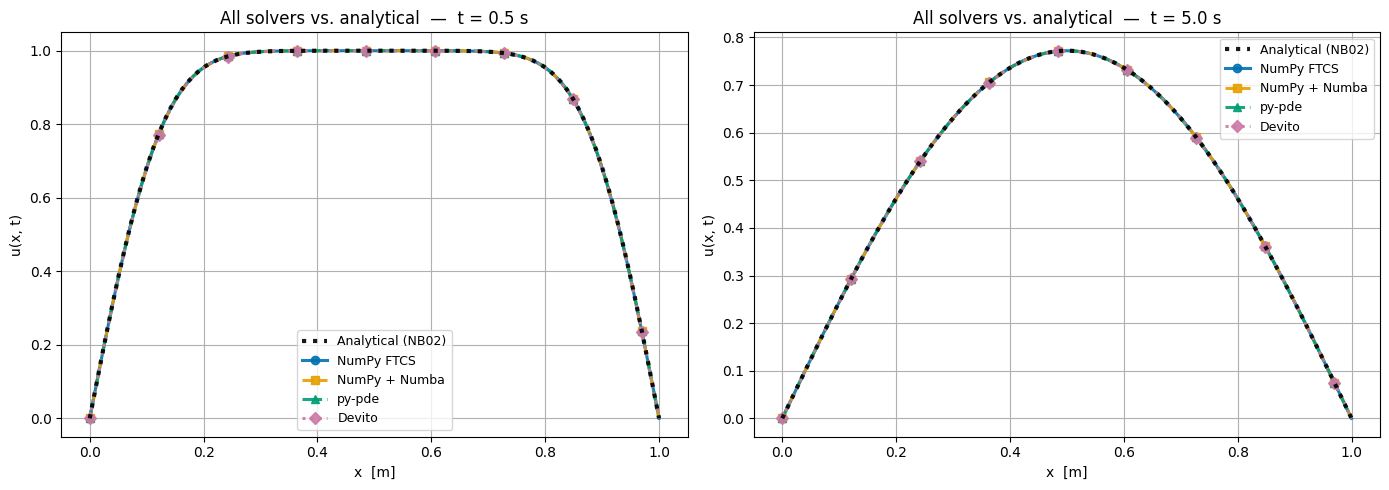

In [35]:
fig, axes = plt.subplots(1, len(SNAP_TIMES), figsize=(7 * len(SNAP_TIMES), 5))
if len(SNAP_TIMES) == 1:
    axes = [axes]

for ax, t_snap in zip(axes, SNAP_TIMES):
    # Analytical reference
    u_analytical = analytical_solution(x_ref, t_snap)
    ax.plot(x_ref, u_analytical, 'k:', lw=3, label='Analytical (NB02)',
            zorder=10, alpha=0.9)
    ax.grid(visible=True)

    # All four numerical solvers
    for label, (key, color, ls, mk) in solvers.items():
        snap = snapshots[(label, t_snap)]
        ax.plot(x_ref, snap, color=color, ls=ls, lw=2.2, label=label, alpha=0.9,
                marker=mk, markevery=12, markersize=6)

    ax.set(title=f'All solvers vs. analytical  —  t = {t_snap} s',
           xlabel='x  [m]', ylabel='u(x, t)')
    ax.legend(fontsize=9)
    ax.grid(visible=True)

plt.tight_layout()
plt.show()

### 7.4 Error plots: pointwise difference from the analytical solution

The snapshot plots show whether the solutions look the same. The error plots show
*where* and *how much* they differ — which may be invisible in the snapshot view if
the differences are small relative to the solution amplitude.

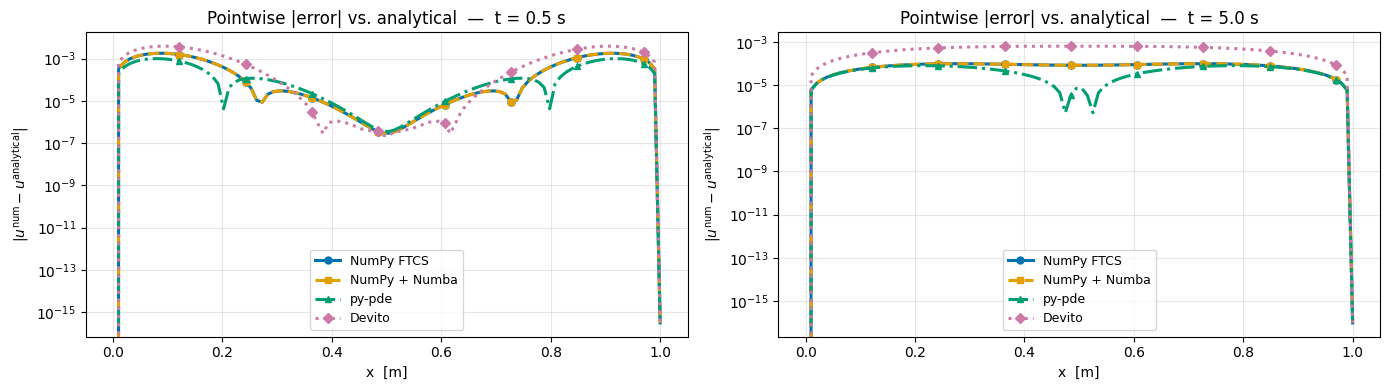

In [36]:
fig, axes = plt.subplots(1, len(SNAP_TIMES), figsize=(7 * len(SNAP_TIMES), 4))
if len(SNAP_TIMES) == 1:
    axes = [axes]

for ax, t_snap in zip(axes, SNAP_TIMES):
    u_analytical = analytical_solution(x_ref, t_snap)
    for label, (key, color, ls, mk) in solvers.items():
        snap  = snapshots[(label, t_snap)]
        error = np.abs(snap - u_analytical)
        ax.plot(x_ref, error, color=color, ls=ls, lw=2.2, label=label,
                marker=mk, markevery=12, markersize=5)

    ax.set(title=f'Pointwise |error| vs. analytical  —  t = {t_snap} s',
           xlabel='x  [m]', ylabel=r'$|u^{\rm num} - u^{\rm analytical}|$')
    ax.set_yscale('log')
    ax.legend(fontsize=9)
    ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

### 7.5 Quantitative error table

We now compute both error metrics — **max absolute error** and **L² error** — for
every solver at every snapshot time, and display them in a structured table.

This is what a professional validation report looks like: not a visual check, but
a quantitative measurement with explicit numbers that can be compared, tracked, and
reported.

**What the errors tell us:**
- Errors of the order $10^{-4}$–$10^{-3}$ are consistent with the **truncation error
  of the FTCS scheme** at the shared $\Delta x$ and $\Delta t$
- The analytical reference itself has a truncation error of order $10^{-5}$ from the
  50-mode truncation — so errors below that level would be coincidental
- All four solvers should show similar errors if they are all implementing the same
  FTCS scheme correctly with the same parameters

In [37]:
print("=" * 75)
print(f"{'Solver':<18} {'Time [s]':>8}  {'Max |error|':>13}  {'L² error':>12}  {'Status'}")
print("=" * 75)

for t_snap in SNAP_TIMES:
    u_analytical = analytical_solution(x_ref, t_snap)
    for label in solvers:
        snap      = snapshots[(label, t_snap)]
        err_abs   = np.abs(snap - u_analytical)
        max_err   = err_abs.max()
        l2_err    = np.sqrt(np.mean(err_abs**2))

        # Flag: errors below 1e-2 are acceptable for FTCS at this grid resolution
        ok = "✓ OK" if max_err < 1e-2 else "✗ HIGH"
        print(f"  {label:<16} {t_snap:>8.1f}  {max_err:>13.2e}  {l2_err:>12.2e}  {ok}")
    print("-" * 75)

print()
print("Notes:")
print(f"  Shared grid: Nx={Nx}, r≈0.4, T_end={T_end} s, N_modes={N_modes} (analytical)")
print(f"  Max error threshold 1e-2 is generous for a teaching context.")
print(f"  At finer grids (larger Nx), errors decrease as O(Δx²) and O(Δt).")
print()
print("Error sources:")
print("  1. FTCS spatial truncation: O(Δx²) — dominant at coarse grids")
print("  2. FTCS time truncation:    O(Δt)  — forward difference in time is first-order")
print("  3. Analytical truncation:  O(e^{-α(Nπ/L)²t}) — exponentially small for N=50")

Solver             Time [s]    Max |error|      L² error  Status
  NumPy FTCS            0.5       1.81e-03      8.14e-04  ✓ OK
  NumPy + Numba         0.5       1.81e-03      8.14e-04  ✓ OK
  py-pde                0.5       1.01e-03      4.27e-04  ✓ OK
  Devito                0.5       3.91e-03      1.84e-03  ✓ OK
---------------------------------------------------------------------------
  NumPy FTCS            5.0       9.80e-05      7.99e-05  ✓ OK
  NumPy + Numba         5.0       9.80e-05      7.99e-05  ✓ OK
  py-pde                5.0       7.93e-05      5.35e-05  ✓ OK
  Devito                5.0       6.36e-04      4.92e-04  ✓ OK
---------------------------------------------------------------------------

Notes:
  Shared grid: Nx=100, r≈0.4, T_end=5.0 s, N_modes=50 (analytical)
  Max error threshold 1e-2 is generous for a teaching context.
  At finer grids (larger Nx), errors decrease as O(Δx²) and O(Δt).

Error sources:
  1. FTCS spatial truncation: O(Δx²) — dominant at coarse 

### 7.6 Four-solver comparison plot

For completeness — a single plot showing all four numerical solvers at the final
time alongside the analytical solution.

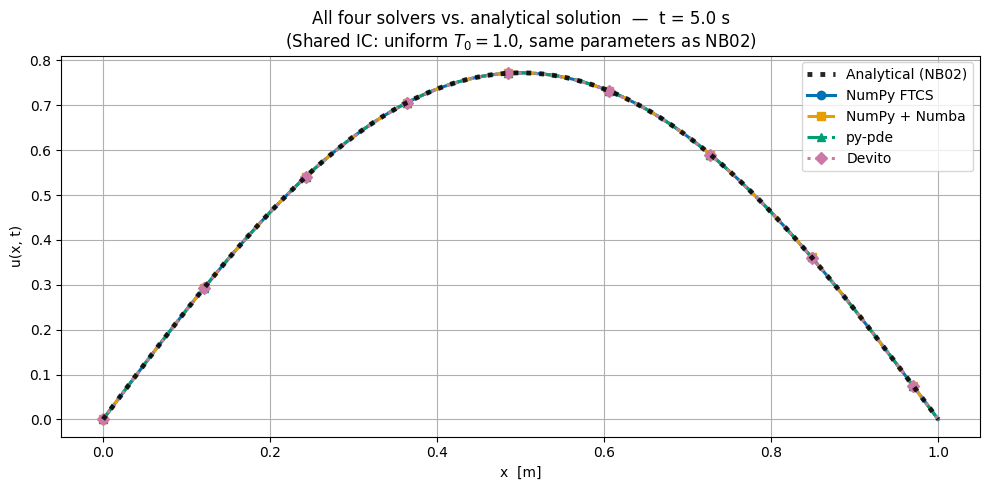

All four solvers solve the same problem with the same parameters.
Remaining differences are purely numerical (FTCS truncation error).
See the error table above for quantitative comparison.


In [41]:
fig, ax = plt.subplots(figsize=(10, 5))

# Analytical reference
u_analytical_end = analytical_solution(x_ref, SNAP_TIMES[-1])
ax.plot(x_ref, u_analytical_end, 'k:', lw=3.5, label='Analytical (NB02)',
        zorder=10, alpha=0.85)

# Four numerical solvers
for label, (key, color, ls, mk) in solvers.items():
    snap = snapshots[(label, SNAP_TIMES[-1])]
    ax.plot(x_ref, snap, color=color, ls=ls, lw=2.2, label=label,
            marker=mk, markevery=12, markersize=6)

ax.set(title=f'All four solvers vs. analytical solution  —  t = {SNAP_TIMES[-1]} s\n'
             f'(Shared IC: uniform $T_0={T0_val}$, same parameters as NB02)',
       xlabel='x  [m]', ylabel='u(x, t)')
ax.legend(fontsize=10)
plt.tight_layout()
plt.grid()
plt.show()

print("All four solvers solve the same problem with the same parameters.")
print("Remaining differences are purely numerical (FTCS truncation error).")
print("See the error table above for quantitative comparison.")

---

## 8. Full-potential benchmark: all solvers at large scale

### 8.1 When the choice of solver matters

For the small shared grid ($N_x = 100$, $T_{\text{end}} = 5$ s), all four solvers
run in under a second — the choice doesn't matter. This section scales up to a grid
where the solver choice becomes significant, demonstrating the **full potential of each
approach**. This is the grid size range you will encounter in 2D problems, fine
1D simulations, and long-time integrations.

We benchmark at:
- $N_x = 500$, $T_{\text{end}} = 10$ s — a moderately large 1D problem

For each solver we report:
- **Wall-clock time** (how long the user waits)
- **Steps per second** (throughput — useful for comparing across different grid sizes)
- **Final max error vs. analytical** (correctness doesn't degrade with scale)

### 8.2 py-pde and Devito benchmark notes

- **py-pde** at large scale uses internal optimisations (compiled backends available
  as options); here we use the default setting.
- **Devito** generates C code once and caches it — the benchmark time excludes
  compilation (already done in Section 6). At this scale, Devito's C kernel runs
  without Python overhead.

> **What to expect:** NumPy is fast due to vectorised operations, but its time-step
> loop is still Python-interpreted. Numba should be significantly faster. py-pde adds
> overhead from its object model. Devito's C code should be competitive with Numba at
> this scale.

In [43]:
import time

Nx_bm  = 500
T_bm   = 10.0
dx_bm  = L_val / (Nx_bm - 1)
dt_bm  = 0.4 * dx_bm**2 / alpha_val
Nt_bm  = int(np.ceil(T_bm / dt_bm)) + 1
print(f"Benchmark: Nx={Nx_bm}, T_end={T_bm} s, Nt={Nt_bm} steps")
print()

results_bm = {}   # label -> (elapsed_s, U_final)

# ── NumPy ─────────────────────────────────────────────────────────────────────
# Baseline: pure NumPy with a vectorised slice update over all interior points.
# The time-stepping loop is interpreted Python — fast per iteration (NumPy ops)
# but the loop itself carries interpreter overhead on every step.
t0 = time.perf_counter()
x_bm, t_bm, U_bm_np = solve_heat_ftcs(
    L=L_val, T_end=T_bm, Nx=Nx_bm, alpha=alpha_val,
    ic_func=ic_uniform, verbose=False)
elapsed_np = time.perf_counter() - t0
results_bm['NumPy FTCS'] = (elapsed_np, U_bm_np[-1].copy())

# ── Numba ─────────────────────────────────────────────────────────────────────
# Numba JIT-compiles the inner spatial loop to native machine code.
# Compilation already happened during warm-up (Section 4), so this measures
# true steady-state runtime with no compilation overhead included.
# The explicit i-loop Numba runs is typically faster than NumPy's slice version
# because it avoids allocating temporary arrays for intermediate results.
t0 = time.perf_counter()
x_bm_nb, t_bm_nb, U_bm_nb = solve_heat_ftcs_numba(
    L=L_val, T_end=T_bm, Nx=Nx_bm, alpha=alpha_val,
    ic_func=ic_uniform, verbose=False)
elapsed_nb = time.perf_counter() - t0
results_bm['NumPy + Numba'] = (elapsed_nb, U_bm_nb[-1].copy())

# ── py-pde ────────────────────────────────────────────────────────────────────
# py-pde uses a high-level solver API: we hand it the PDE object and initial
# state and it handles time-stepping internally. At this scale it uses its
# default explicit Euler backend, which is similar to our NumPy solver but
# carries additional overhead from its object model and boundary-condition
# dispatch. For larger or more complex problems, py-pde can switch to faster
# compiled backends automatically.
grid_bm   = pde.CartesianGrid([[0, L_val]], [Nx_bm])
x_bm_pde  = grid_bm.axes_coords[0]
state_bm  = pde.ScalarField(grid_bm, data=ic_uniform(x_bm_pde))
eq_bm     = pde.DiffusionPDE(diffusivity=alpha_val, bc={"value": 0})
t0 = time.perf_counter()
result_bm_pde = eq_bm.solve(state_bm, t_range=T_bm, dt=dt_bm)
elapsed_pde = time.perf_counter() - t0
pde_bm_interp = interp1d(x_bm_pde, result_bm_pde.data,
                          kind='linear', bounds_error=False, fill_value=0.0)
results_bm['py-pde'] = (elapsed_pde, pde_bm_interp(x_bm))

# ── Devito ────────────────────────────────────────────────────────────────────
# Devito generates optimised C code from the symbolic stencil and compiles it
# with gcc at runtime (cached after the first run in Section 6, so no
# recompilation happens here). The compiled C kernel runs with no Python
# overhead inside the time loop — only the outer op.apply() call touches Python.
#
# Stencil note: we write  u.forward = u + alpha * dt * u.dx2  and pass dt as a
# runtime argument to op.apply(). Devito substitutes dt and the grid spacing dx
# automatically when generating the C code, so the compiled kernel uses the
# correct finite-difference coefficients. Writing r * u.dx2 with a precomputed
# scalar r does NOT work — Devito treats u.dx2 as a continuous derivative and
# only discretises it when it can see the physical parameters (alpha, dt, dx)
# in symbolic form.
from devito import Grid, TimeFunction, Eq, Operator
grid_dv_bm  = Grid(shape=(Nx_bm,), extent=(L_val,))
u_dv_bm     = TimeFunction(name='u_bm', grid=grid_dv_bm, time_order=1, space_order=2)
x_dv_bm     = np.linspace(0, L_val, Nx_bm)
u_dv_bm.data[0][:]  = ic_uniform(x_dv_bm)   # set initial condition in time slot 0
u_dv_bm.data[0][0]  = 0.0                    # enforce left  Dirichlet BC at t=0
u_dv_bm.data[0][-1] = 0.0                    # enforce right Dirichlet BC at t=0
t_d2, x_d2  = u_dv_bm.dimensions
stencil_bm  = Eq(u_dv_bm.forward, u_dv_bm + alpha_val * dt_bm * u_dv_bm.dx2)
bc_l_bm     = Eq(u_dv_bm[t_d2+1, 0],        0)   # u(0,   t_{n+1}) = 0
bc_r_bm     = Eq(u_dv_bm[t_d2+1, Nx_bm-1],  0)   # u(L,   t_{n+1}) = 0
op_bm       = Operator([stencil_bm, bc_l_bm, bc_r_bm], name='HeatBM')
t0 = time.perf_counter()
op_bm.apply(time_M=Nt_bm - 1, dt=dt_bm)
elapsed_dv  = time.perf_counter() - t0
# Rolling buffer: after Nt_bm steps the final solution is in slot Nt_bm % 2.
results_bm['Devito'] = (elapsed_dv, u_dv_bm.data[Nt_bm % 2][:].copy())

# ── Summary table ─────────────────────────────────────────────────────────────
# We compare each solver's final snapshot against the analytical solution to
# confirm that speed differences do not come at the cost of accuracy — all four
# should show errors at the same FTCS truncation level (~O(dx^2)).
x_bm_ref    = x_bm
u_bm_analyt = analytical_solution(x_bm_ref, T_bm)

print(f"{'Solver':<18} {'Time (s)':>10}  {'Steps/s':>10}  {'Max err vs analyt':>18}  Speedup vs NumPy")
print("=" * 82)
t_numpy_bm = results_bm['NumPy FTCS'][0]
for label, (elapsed, U_fin) in results_bm.items():
    if len(U_fin) != len(x_bm_ref):
        f_interp = interp1d(np.linspace(0, L_val, len(U_fin)), U_fin,
                             kind='linear', bounds_error=False, fill_value=0.0)
        U_ref = f_interp(x_bm_ref)
    else:
        U_ref = U_fin
    max_err = np.max(np.abs(U_ref - u_bm_analyt))
    sps     = Nt_bm / elapsed
    speedup = t_numpy_bm / elapsed
    print(f"  {label:<16} {elapsed:>10.3f}  {sps:>10.0f}  {max_err:>18.2e}  {speedup:>6.1f}×")
print()
print("All errors vs analytical are at FTCS truncation level (not solver quality).")

Benchmark: Nx=500, T_end=10.0 s, Nt=62252 steps



  0%|          | 0/10.0 [00:00<?, ?it/s]

Solver               Time (s)     Steps/s   Max err vs analyt  Speedup vs NumPy
  NumPy FTCS            1.026       60666            3.71e-06     1.0×
  NumPy + Numba         0.076      823778            3.71e-06    13.6×
  py-pde                4.229       14720            7.48e-06     0.2×
  Devito                0.172      361875            3.94e-06     6.0×

All errors vs analytical are at FTCS truncation level (not solver quality).


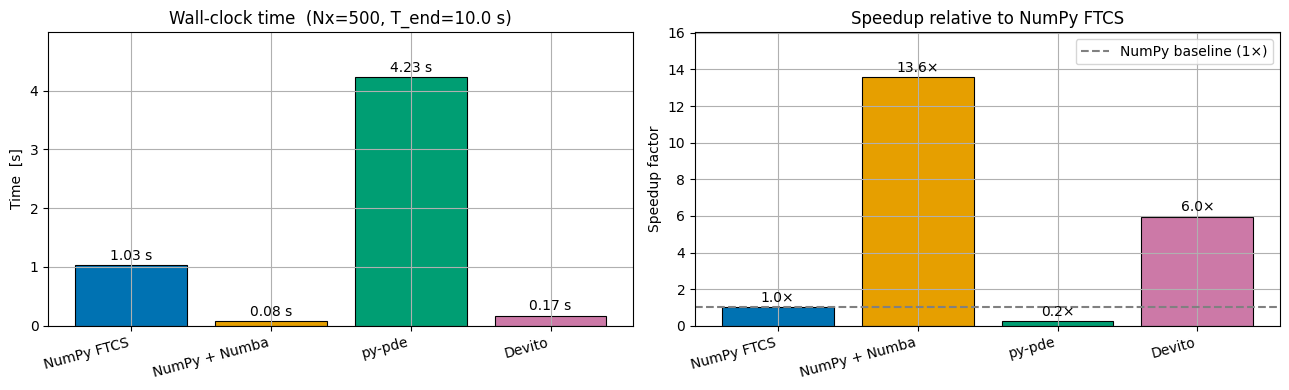


Take-away:
  • NumPy + Numba: same accuracy as NumPy, significant speedup, stays in Python.
  • py-pde: convenient API, comparable or slightly slower at this scale.
  • Devito: C-generated code — competitive at this scale, scales to 2D/3D and HPC.


In [46]:
# ── Benchmark bar chart ───────────────────────────────────────────────────────
labels   = list(results_bm.keys())
times    = [results_bm[l][0] for l in labels]
colors_b = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']  # Okabe-Ito

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: wall-clock time
bars = axes[0].bar(labels, times, color=colors_b, edgecolor='black', linewidth=0.8)
axes[0].set(title=f'Wall-clock time  (Nx={Nx_bm}, T_end={T_bm} s)',
            ylabel='Time  [s]')
axes[0].set_xticks(range(len(labels)))
axes[0].set_xticklabels(labels, rotation=15, ha='right')
axes[0].set_ylim(top=max(times) * 1.18)  # headroom for value labels
axes[0].grid(True)
for bar, t_val in zip(bars, times):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(times)*0.01,
                 f'{t_val:.2f} s', ha='center', va='bottom', fontsize=10)

# Right: speedup relative to NumPy
speedups = [t_numpy_bm / t for t in times]
bars2    = axes[1].bar(labels, speedups, color=colors_b, edgecolor='black', linewidth=0.8)
axes[1].axhline(1.0, color='gray', linestyle='--', lw=1.5, label='NumPy baseline (1×)')
axes[1].set(title='Speedup relative to NumPy FTCS', ylabel='Speedup factor')
axes[1].set_xticks(range(len(labels)))
axes[1].set_xticklabels(labels, rotation=15, ha='right')
axes[1].set_ylim(top=max(speedups) * 1.18)  # headroom for value labels
axes[1].legend()
axes[1].grid(True)
for bar, sp in zip(bars2, speedups):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(speedups)*0.01,
                 f'{sp:.1f}\u00d7', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("\nTake-away:")
print("  • NumPy + Numba: same accuracy as NumPy, significant speedup, stays in Python.")
print("  • py-pde: convenient API, comparable or slightly slower at this scale.")
print("  • Devito: C-generated code — competitive at this scale, scales to 2D/3D and HPC.")

---

## 10. How to choose an FDTD scheme for any PDE

Everything you have done in this notebook — deriving the FTCS stencil, enforcing
boundary conditions, checking stability, verifying against an analytical solution —
was for one specific PDE: the heat equation. But the **methodology** is universal.
Any time-dependent PDE can be discretised using the same process.

This section gives you the classification framework. Given any PDE, you can work
through these steps systematically and determine what kind of scheme you need —
before writing a single line of code.

---

### Step 1 — Count the time derivatives. This is the most important question.

The number of time derivatives in a PDE is not a detail — it determines the
fundamental mathematical character of the equation and the entire class of
discretisation that is appropriate.

**One time derivative → parabolic equation**

The equation describes a *dissipative* process. Information flows in one direction
in time only — the past affects the future, but not vice versa. The system loses
energy. Given a state at time $t$, the future is uniquely determined but the past
cannot be recovered.

Discretisation consequence: use a **forward (or backward) difference in time**.
The forward difference is explicit — cheap per step but conditionally stable.
The backward difference (implicit) is unconditionally stable but requires solving
a linear system at every step.

> Example term: $\partial_t u$ — one time derivative.

**Two time derivatives → hyperbolic equation**

The equation describes a *wave-like* process. Information propagates at finite
speed in both directions. Energy is conserved (in the absence of damping). The
system has memory — you need to know *two* time levels ($t_n$ and $t_{n-1}$)
to advance to $t_{n+1}$.

Discretisation consequence: use a **central difference in time (leapfrog)**.
The leapfrog stencil is time-symmetric, which preserves the oscillatory character
of the solution. Using a forward difference on a hyperbolic equation destroys this
symmetry and typically produces an unstable or heavily dissipative scheme.

> Example term: $\partial_t^2 u$ — two time derivatives.

**Critical rule:** leapfrog is unconditionally unstable for parabolic equations.
FTCS is wrong for hyperbolic equations. The PDE type is not a preference — it
determines the correct scheme family. This is not negotiable.

---

### Step 2 — Identify the spatial derivative orders. This determines stencil width.

Each spatial term in the PDE requires a minimum number of neighbouring grid points
to approximate its derivative. This is the **stencil width**.

**Second-order spatial derivative → three-point stencil**

$$\frac{\partial^2 u}{\partial x^2} \approx \frac{u_{i+1} - 2u_i + u_{i-1}}{\Delta x^2}$$

Requires one neighbour to the left and one to the right of point $i$.
This is the stencil you used throughout this notebook.

**Fourth-order spatial derivative → five-point stencil**

$$\frac{\partial^4 u}{\partial x^4} \approx \frac{u_{i+2} - 4u_{i+1} + 6u_i - 4u_{i-1} + u_{i-2}}{\Delta x^4}$$

Requires two neighbours on each side. This wider stencil has two important
consequences:

- **Boundary treatment becomes more complex.** A three-point stencil only needs
  the value of $u$ at the boundary. A five-point stencil reaches two points
  inside the domain — the boundary condition must specify enough information to
  fill those extra points. For physical problems, this typically means specifying
  conditions on both $u$ and its second derivative at each boundary.

- **The CFL condition becomes more restrictive.** The stability constraint for a
  fourth-order spatial term involves $\Delta x^4$ in the denominator, meaning the
  maximum stable time step shrinks much faster as you refine the spatial grid.
  Halving $\Delta x$ requires 16 times as many time steps (not 4 as with the
  three-point stencil).

**When a PDE contains both orders**, the five-point stencil must be used — the
stencil must accommodate the widest spatial derivative in the equation.

---

### Step 3 — Identify damping terms and their character.

Damping introduces a first time derivative alongside the dominant time derivative.
It is not just a minor correction — it changes the discretisation requirements
and must be handled deliberately.

There are two qualitatively different types of damping, and they are not the same
thing numerically or physically.

**Frequency-independent damping**

A term of the form $\sigma \, \partial_t u$ damps all spatial modes at the same
rate regardless of their wavenumber. A low-frequency mode and a high-frequency
mode lose energy at the same rate per unit time. This is the simpler case.

Discretisation: the $\partial_t u$ term can be approximated with a forward,
backward, or central difference in time. The choice affects accuracy and stability.
Central difference (averaging $t_{n+1}$ and $t_{n-1}$) is second-order accurate
but introduces an implicit coupling that may require rearranging the update equation.

**Frequency-dependent damping**

A term that couples a time derivative with a spatial derivative — such as
$\sigma \, \partial_t \partial_x^2 u$ — damps different spatial modes at
*different rates*. High spatial frequencies (rapidly varying modes) are damped
more strongly than low spatial frequencies (slowly varying modes). This is
physically richer and numerically more demanding.

Why numerically harder? Because the term mixes the time and space discretisations.
You cannot handle it by just adding a time-difference term — you must apply a
spatial difference operator *and* a time difference operator together, and the
stability of the coupled result depends on how both are chosen.

**How to tell them apart:** look at whether the damping term involves only a time
derivative, or a time derivative *of a spatial operator*. If it involves both, it
is frequency-dependent.

---

### Step 4 — Identify mixed derivatives explicitly.

A mixed derivative like $\partial_t \partial_x^2 u$ is not a new kind of object —
it is the composition of two operators you already know. But it deserves explicit
recognition as a term in the PDE because:

- It couples the time and space discretisation decisions
- It contributes its own term to the stability condition
- It may require special treatment at the boundaries (where the spatial stencil
  reaches outside the domain)

The discretisation approach: apply the spatial difference operator first
(e.g. the three-point stencil for $\partial_x^2$) to get a new quantity at each
interior grid point, then apply the time difference operator to that quantity.
The order matters for implementation, and the choice of forward/central/backward
for the time part affects the stability of the whole scheme.

---

### Step 5 — Write down all your discretisation decisions before coding.

This is the step most students skip, and it is the reason most implementations
fail on the first attempt.

Before writing any update equation or any loop, answer these questions in writing:

1. How many time derivatives does my PDE have? What does that tell me about the
   scheme family?
2. What is the highest spatial derivative order? What stencil width does that require?
3. Do I have a damping term? Is it frequency-independent or frequency-dependent?
4. Do I have any mixed derivatives? How will I discretise each part?
5. How many time levels does my scheme need? (Leapfrog needs two: $n$ and $n-1$.)
6. What are my boundary conditions, and do they provide enough information for
   my stencil width? (Five-point stencils at the boundary need extra information.)
7. What is the structure of my CFL condition? Which term in the PDE will make
   it most restrictive?

Only after answering all seven questions should you write the update equation.

---

### Step 6 — Understand how the terms interact in the stability condition.

The CFL condition for a PDE with multiple terms is **not** the sum of the individual
terms' conditions. The stability of the full scheme comes from analysing the complete
stencil — all terms together.

However, there is a practical heuristic: **the most restrictive term usually
dominates.** A fourth-order spatial term with its $\Delta x^4$ denominator will
typically force a much smaller time step than a second-order term alone. A
frequency-dependent damping term adds its own constraint. When you have several
terms, start by identifying which one is likely to set the tightest CFL bound —
that term should drive your grid design.

This also means: when you refine your spatial grid to get more accurate results,
the time step must shrink to satisfy the most restrictive CFL condition. For
high-order spatial terms, this cost can be severe. This is one reason why
practitioners turn to implicit schemes or operator splitting for equations with
fourth-order spatial terms — not because explicit schemes are wrong, but because
the quadratic (or worse) cost of grid refinement makes them impractical at scale.

---

### Summary: the classification checklist

Before discretising any PDE, fill in this table:

| Question | Answer | Implication |
|---|---|---|
| Number of time derivatives | 1 (parabolic) or 2 (hyperbolic) | Forward/backward in time vs. leapfrog |
| Highest spatial derivative order | 2nd or 4th (or higher) | 3-point or 5-point stencil |
| Damping term present? | Yes / No | Adds a first time derivative term |
| Damping type | Frequency-independent or frequency-dependent | Simple or mixed discretisation |
| Mixed derivatives? | Yes / No | Requires composed discretisation |
| Time levels needed | 1 (parabolic) or 2 (hyperbolic) | Storage and IC requirements |
| Boundary condition information | Values only, or values + derivatives | Depends on stencil width |
| Most restrictive CFL term | Which spatial order dominates | Drives grid design |

This table is your design document. Fill it in completely before you write any code.

---

### A note on initial conditions

This is easy to overlook but bites students repeatedly.

A parabolic equation (one time derivative) needs **one** initial condition:
the value of $u$ at $t = 0$. That is what you provided in this notebook: the
initial temperature profile.

A hyperbolic equation (two time derivatives) needs **two** initial conditions:
the value of $u$ at $t = 0$, *and* the time derivative $\partial_t u$ at $t = 0$.
Physically, this means specifying both the initial displacement and the initial
velocity. A leapfrog scheme needs both to start, because it requires $u$ at two
time levels before it can advance.

How do you initialise a leapfrog scheme from $\partial_t u$ at $t = 0$? This
requires a careful one-step bootstrapping procedure — typically using a half-step
or a Taylor expansion. It is a standard part of any leapfrog implementation and
must be done correctly, or the scheme introduces a spurious initial error that
contaminates the entire simulation.


---

## 11. Summary

**What you now know:**

1. **FDTD** is a general method for solving time-dependent PDEs on a discrete grid.
   **FTCS** (Forward-in-Time, Central-in-Space) is one specific scheme within the FDTD
   family — the simplest explicit choice for parabolic (diffusion) equations.

2. The central difference in space is **second-order accurate** (error $\propto \Delta x^2$);
   the forward difference in time is first-order. Together they give the FTCS update:
   $u_i^{n+1} = u_i^n + r(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$.

3. The **CFL condition** $r = \alpha \Delta t / \Delta x^2 \leq 1/2$ is a hard
   stability constraint. Violating it causes numerical blow-up. Finer grids force
   smaller time steps — a quadratic cost that motivates faster solvers.

4. **NumPy + Numba** is the professional Python default for FDTD: add `@njit` to
   the time-stepping loop, get near-C speed, stay in Python. First call compiles;
   subsequent calls run from cached machine code.

5. **py-pde** provides a high-level symbolic API — define the PDE and boundary
   conditions, let the library handle discretisation and time-stepping. Always
   specify `bc={"value": 0}` for Dirichlet conditions.

6. **Devito** generates optimised C code from symbolic stencils — the same
   approach used in large-scale wave and acoustic simulations. The key detail:
   `TimeFunction` uses a rolling buffer; extract the final solution with
   `u.data[Nt % 2]`.

7. **All four solvers solve the same problem correctly** (verified against the
   analytical solution from NB02) with errors at the level of FTCS truncation
   accuracy. They disagree only in speed, API complexity, and scalability.

8. **The choice of FDTD scheme is determined by the PDE, not by preference.**
   Parabolic equations need forward-in-time schemes. Hyperbolic equations need
   central-in-time (leapfrog) schemes. Using the wrong scheme family produces
   results that are either unconditionally unstable or physically wrong. The
   classification framework in Section 10 gives you the tools to make this
   determination for any PDE you encounter.

**Solver selection guide:**

| Situation | Recommended tool |
|---|---|
| Learning, full control, understanding every step | NumPy from scratch |
| Performance-critical 1D/2D, stay in Python | NumPy + Numba |
| Rapid prototyping, varied BCs, varied PDE forms | py-pde |
| Large-scale, production, HPC, 2D/3D problems | Devito |

---

<div style="text-align:center; padding:18px 0 8px 0; margin-top:24px; border-top:2px solid #e0e0e0;">
  <p style="margin:0 0 6px 0;">
    <b>Forschungsseminar – Medieningenieurwissenschaften</b> &middot; NB03: FDTD Simulation<br>
    Institut für Medientechnik – Technische Universität Ilmenau
  </p>
  <p style="margin:0; font-size:0.95em;">
    Notebook created by <b>Renato Fera P.</b> &middot;
    <a href="https://www.linkedin.com/in/renato-profeta/" target="_blank">LinkedIn</a>
  </p>
</div>